# 🔗 Live Web Application (Cloud Deployment Link)

**DEPLOYMENT_URL = `PLACEHOLDER – replace with your real, tested Streamlit Community Cloud link after deployment (see Step 13)`**

> ⚠️ This is intentionally a placeholder. The app has **not** been deployed by the author of this notebook yet, so no link is claimed here. Replace this line with the verified live URL before submitting to Google Classroom.

---

# Bike Rental Demand Prediction System – 10-Fold Cross Validation (Full Dataset)

## Setup: Running This Notebook on Google Colab

No installation is needed. Google Colab already has every library this notebook uses (`pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`, `joblib`, `tqdm`).

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. **Step 2.1** looks for `data/hour.csv`. If it is not there it tries to download the official UCI zip automatically; if the download is blocked it shows a **"Choose Files"** button so you can upload `hour.csv` (or the whole `bikesharingdataset.zip`).

> **Run time:** the 10-fold cross validation (Step 8) trains 50 models. SVR is the slowest (about a minute per fold on a normal CPU), so expect **roughly 10–20 minutes** in total. A progress bar with elapsed and remaining time is shown. The optional day-grouped check in Step 9.6 repeats the experiment once more, so allow about the same time again.
>
> **Note:** Colab deletes files when the runtime is reset. If a file is "not found", just run Step 2.1 again.

---

> **Execution record of the outputs stored in this file.** These outputs were generated by running this notebook top to bottom (no cell edited afterwards) in a Linux cloud container on **CPU only (2 cores)** with Python 3.13, NumPy 2.5.3, pandas 3.0.5, scikit-learn 1.9.1 and Matplotlib 3.11.2 (see Step 1). Run times in the tables (e.g. SVR ≈ 573 s) are from that machine. **The assignment requires the experiment to be run on Google Colab:** run it there (**Runtime → Run all**) and keep the notebook version that Colab saves; Colab may use another scikit-learn version, so use the `requirements.txt` that Step 10.3 writes together with the model file.

## Introduction

##### **Definition** A regression ML task that predicts the **number of bikes rented in a given hour** (`cnt`) from the calendar (hour, weekday, month, year, holiday) and the weather (weather type, temperature, humidity, wind speed).
##### **Application** Bike-sharing fleet allocation (how many bikes to have at each station and when), station planning, rebalancing trucks, staff scheduling, maintenance windows, and operational resource management for city mobility services.

### Aim of This Notebook

> **Which of 5 regression algorithms predicts hourly bike-rental demand best, and how sure can we be about that answer?**

To answer it fairly we use **K-Fold Cross Validation (K = 10)** on the **full labelled dataset** and compare the algorithms using **Root Mean Squared Error (RMSE)**, exactly like the instructor's Car Price notebook, but on a different problem and with **five different algorithms**.

### What is K-Fold Cross Validation?

A single train/test split can be lucky or unlucky. K-Fold removes this luck:

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train on **K−1 folds**, test on the **remaining fold**.
3. Repeat **K times**, so **every fold is the test fold exactly once**.
4. Report the **average** score (and the standard deviation, to show how much it varies).

With K = 10 on the full dataset (17,379 hourly records) each test fold has about 1,738 records and each training set about 15,641:

```
Round  1:  [TEST ] | [train] | [train] | ... | [train]
Round  2:  [train] | [TEST ] | [train] | ... | [train]
   ...
Round 10:  [train] | [train] | [train] | ... | [TEST ]
```

### Evaluation Measure: Root Mean Squared Error (RMSE)

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

- $y_i$ = actual number of rentals in that hour, $\hat{y}_i$ = predicted number, $n$ = number of test records.
- RMSE is in the **same unit as the output (bike rentals per hour)**: "on average, predictions are off by about X bikes".
- **Lower RMSE = better.** Errors are squared, so **large mistakes are penalised heavily** (RMSE ≥ MAE always).
- We also report **MAE** (average absolute error) and **R²** (share of the variation in demand that the model explains) as supporting metrics.

## Input and Output

### Input (Features / Attributes)

| Feature | Description (from the dataset Readme) | Type | Values in the data |
|---|---|---|---|
| **hr** | Hour of the day | Numerical (cyclic) | 0 – 23 |
| **mnth** | Month | Numerical | 1 – 12 |
| **yr** | Year (0 = 2011, 1 = 2012) | Binary | 0, 1 |
| **season** | 1 spring, 2 summer, 3 fall, 4 winter | Categorical | 1 – 4 |
| **weekday** | Day of week | Categorical | 0 – 6 (0 = Sunday, verified in Step 3) |
| **holiday** | Public holiday or not | Binary | 0, 1 |
| **workingday** | Neither weekend nor holiday | Binary | 0, 1 |
| **weathersit** | 1 clear … 4 heavy rain/snow | Categorical | 1 – 4 |
| **temp** | Normalised temperature | Numerical | 0 – 1 |
| **atemp** | Normalised "feels-like" temperature | Numerical | 0 – 1 |
| **hum** | Normalised humidity | Numerical | 0 – 1 |
| **windspeed** | Normalised wind speed | Numerical | 0 – 0.85 |

**Not used as inputs:** `instant` (just a row number), `dteday` (its information is already in `yr`, `mnth`, `weekday`), and **`casual` and `registered`** – they add up exactly to the target (`cnt = casual + registered`), so using them would be **target leakage** (see Step 5).

### Output (Prediction)

| Output Attribute | Description | Data Type |
|---|---|---|
| **cnt** | Total number of bikes rented in that hour (casual + registered users) | Integer count |

## Developer & System Information

| **Attribute** | **Details** |
|---|---|
| **Developer Name** | `[Your Name]` – `[Your Registration No.]` |
| **Course** | Machine Learning Fundamentals (AIC354), Assignment 3 – Task 2 |
| **Program Name** | `bike_rental_kfold_full_dataset_10fold` |
| **IDE** | Google Colab |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, scikit-learn, Matplotlib, Seaborn, Joblib, tqdm. Exact versions are printed in Step 1. |
| **Dataset** | UCI Bike Sharing Dataset – `hour.csv` (17,379 hourly records, 17 attributes; verified in Step 2) |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load Data (2.1 Get the dataset, 2.2 Read it)
- **Step 3:** Understand the Data (3.1 Structure & quality, 3.2 Data-integrity checks, 3.3 The target)
- **Step 4:** Exploratory Data Analysis (EDA)
- **Step 5:** Pre-processing, Feature Engineering and Leakage Prevention
- **Step 6:** Define the 5 Regression Algorithms
- **Step 7:** Set Up 10-Fold Cross Validation
- **Step 8:** Run 10-Fold Cross Validation for All 5 Algorithms
- **Step 9:** Compare the Algorithms (9.1 per-fold RMSE, 9.2 summary, 9.3 charts, 9.4 observations, 9.5 where do the errors come from, 9.6 extra check: day-grouped CV)
- **Step 10:** Train, Save and Re-load the Final Model
- **Step 11:** Application Phase (prediction from user input)
- **Step 12:** Feedback Phase
- **Step 13:** Web Application and Cloud Deployment
- **Conclusion, Limitations and References**

# Code – Bike Rental Demand Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python libraries ---
import os, io, json, time, shutil, zipfile, warnings, urllib.request
from datetime import datetime, timezone

import numpy as np
import pandas as pd

# --- Machine learning (scikit-learn) ---
import sklearn
import joblib
from sklearn.base import clone
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.exceptions import ConvergenceWarning

# --- The 5 regression algorithms (none of them is used in the Car Price notebooks) ---
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

# --- Visualisation ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import seaborn as sns

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

SEED = 42                      # one seed used everywhere -> reproducible results
np.random.seed(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)

# Chart style: one blue for the data, quiet grey grid, no top/right frame
BLUE, ORANGE = "#2a78d6", "#d9772b"
TEXT_COLOR, MUTED_TEXT, GRID_COLOR = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID_COLOR, "axes.labelcolor": MUTED_TEXT, "xtick.color": MUTED_TEXT,
    "ytick.color": MUTED_TEXT, "axes.titlecolor": TEXT_COLOR, "axes.titlesize": 12,
    "axes.titleweight": "regular", "axes.titlelocation": "left", "axes.grid": True,
    "grid.color": GRID_COLOR, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")
print(f"  Seaborn      : {sns.__version__}")
print(f"  Joblib       : {joblib.__version__}")

Library versions used in this run:
  NumPy        : 2.5.3
  Pandas       : 3.0.5
  scikit-learn : 1.9.1
  Matplotlib   : 3.11.2
  Seaborn      : 0.13.2
  Joblib       : 1.6.0


# Step 2: Load Data
## Step 2.1: Get the Dataset

**Dataset used:** the **UCI Bike Sharing Dataset** (Fanaee-T & Gama, 2013) – <https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset>. It is the *same* Capital Bikeshare (Washington, D.C.) data that the Kaggle "Bike Sharing Demand" competition is built from, but the UCI version is the better choice for this assignment because **every one of its 17,379 hourly rows is labelled** with the real rental count `cnt`.

> The Kaggle competition provides a *labelled* `train.csv` (10,886 rows – only days 1–19 of each month) and an *unlabelled* `test.csv` (no counts, only usable for a leaderboard score). The UCI `hour.csv` contains the complete, fully labelled two-year record, which is what 10-fold cross validation needs. The unlabelled test set is **never used** here.

The cell below uses `data/hour.csv` if it exists. Otherwise (e.g. on a fresh Colab runtime) it tries to download the official UCI zip, and as a last resort asks you to upload `hour.csv` or the zip.

In [2]:
DATA_DIR  = "data"
DATA_FILE = os.path.join(DATA_DIR, "hour.csv")
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def _extract_zip(zip_bytes):
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
        for member in z.namelist():
            if os.path.basename(member) in ("hour.csv", "day.csv", "Readme.txt"):
                with open(os.path.join(DATA_DIR, os.path.basename(member)), "wb") as f:
                    f.write(z.read(member))

os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(DATA_FILE) and os.path.exists("hour.csv"):      # file sitting next to the notebook
    shutil.copy("hour.csv", DATA_FILE)

if not os.path.exists(DATA_FILE):
    try:                                                              # 1) try the official UCI download
        print("Downloading the dataset from UCI ...")
        _extract_zip(urllib.request.urlopen(UCI_ZIP_URL, timeout=60).read())
    except Exception as err:
        print(f"Automatic download failed ({type(err).__name__}).")

if not os.path.exists(DATA_FILE) and IN_COLAB:                        # 2) ask the user to upload
    print("Please click 'Choose Files' and select 'hour.csv' (or the whole bikesharingdataset.zip) ...")
    for name, content in files.upload().items():
        if name.lower().endswith(".zip"):
            _extract_zip(content)
        else:
            with open(os.path.join(DATA_DIR, "hour.csv" if "hour" in name.lower() else name), "wb") as f:
                f.write(content)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use  ({os.path.getsize(DATA_FILE)/1024:,.0f} KB).")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload hour.csv.")

'data/hour.csv' is ready to use  (1,130 KB).


## Step 2.2: Read the Dataset

This notebook uses **all** the labelled hourly records (no sampling).

In [3]:
bike = pd.read_csv(DATA_FILE)
print(f"Loaded dataset: {bike.shape[0]:,} rows x {bike.shape[1]} columns")
bike.head()

Loaded dataset: 17,379 rows x 17 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


In [4]:
bike.tail()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.26,0.60,0.16,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.26,0.60,0.16,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.26,0.60,0.16,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.27,0.56,0.13,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.26,0.27,0.65,0.13,12,37,49


# Step 3: Understand the Data
## Step 3.1: Structure and Data Quality

> **Documented facts vs. things we calculate:** the dataset Readme *documents* that `hour.csv` has 17,379 records and describes each column. Everything printed below is *calculated from the file we actually loaded*.

In [5]:
print("Attributes (columns):")
print("=====================")
print(list(bike.columns))

print("\nNumber of instances (labelled hourly records):")
print("==============================================")
print(f"{len(bike):,}   (Readme says 17,379 -> matches: {len(bike) == 17379})")

print("\nData types:")
print("===========")
print(bike.dtypes.to_string())

print("\nMissing values in each attribute:")
print("=================================")
missing = bike.isnull().sum()
print(missing[missing > 0].to_string() if missing.sum() > 0 else "No missing values")

print("\nDuplicate rows:")
print("===============")
print(f"{bike.duplicated().sum():,} fully duplicated rows  |  {bike.duplicated(subset=['dteday', 'hr']).sum():,} duplicated (date, hour) pairs")

Attributes (columns):
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Number of instances (labelled hourly records):
17,379   (Readme says 17,379 -> matches: True)

Data types:
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64

Missing values in each attribute:
No missing values

Duplicate rows:
0 fully duplicated rows  |  0 duplicated (date, hour) pairs


In [6]:
# Descriptive statistics of every numeric column
bike.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,"17,379.00","8,690.00","5,017.03",1.00,"4,345.50","8,690.00","13,034.50","17,379.00"
season,"17,379.00",2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,"17,379.00",0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,"17,379.00",6.54,3.44,1.00,4.00,7.00,10.00,12.00
hr,"17,379.00",11.55,6.91,0.00,6.00,12.00,18.00,23.00
holiday,"17,379.00",0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,"17,379.00",3.00,2.01,0.00,1.00,3.00,5.00,6.00
workingday,"17,379.00",0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,"17,379.00",1.43,0.64,1.00,1.00,1.00,2.00,4.00
temp,"17,379.00",0.50,0.19,0.02,0.34,0.50,0.66,1.00


In [7]:
# Numerical vs categorical summary (the codes are numbers, but season/weekday/weathersit are CATEGORIES, not quantities)
numeric_cols     = ["temp", "atemp", "hum", "windspeed", "hr", "mnth"]
categorical_cols = ["season", "weekday", "weathersit", "yr", "holiday", "workingday"]

print("Value counts of the categorical / binary columns:\n")
for col in categorical_cols:
    counts = bike[col].value_counts().sort_index()
    print(f"{col:<11}: " + ", ".join(f"{k}={v:,}" for k, v in counts.items()))

Value counts of the categorical / binary columns:

season     : 1=4,242, 2=4,409, 3=4,496, 4=4,232
weekday    : 0=2,502, 1=2,479, 2=2,453, 3=2,475, 4=2,471, 5=2,487, 6=2,512
weathersit : 1=11,413, 2=4,544, 3=1,419, 4=3
yr         : 0=8,645, 1=8,734
holiday    : 0=16,879, 1=500
workingday : 0=5,514, 1=11,865


## Step 3.2: Data-Integrity Checks

Before trusting the documentation, we test it. These checks also decide which columns are safe to use.

In [8]:
dates = pd.to_datetime(bike["dteday"])
expected_weekday = (dates.dt.dayofweek + 1) % 7                 # pandas Monday=0 ... Sunday=6  ->  0=Sunday ... 6=Saturday
expected_working = ((bike["weekday"].between(1, 5)) & (bike["holiday"] == 0)).astype(int)
n_days = dates.nunique()

checks = pd.Series({
    "cnt == casual + registered in every row (=> these two columns would LEAK the target)": bool((bike["cnt"] == bike["casual"] + bike["registered"]).all()),
    "weekday matches the calendar date with 0 = Sunday": bool((expected_weekday == bike["weekday"]).all()),
    "workingday == (Mon-Fri and not a holiday) in every row": bool((expected_working == bike["workingday"]).all()),
    "each (date, hour) appears at most once": bool(not bike.duplicated(subset=["dteday", "hr"]).any()),
}, name="check passed?")
print(checks.to_string())

print(f"\nDate range           : {dates.min().date()}  to  {dates.max().date()}  ({n_days} distinct days)")
print(f"Hours that should exist: {n_days} days x 24 = {n_days*24:,}   |   rows present: {len(bike):,}   |   missing hours: {n_days*24 - len(bike):,}")
print("The Readme does not explain the missing hours. A plausible explanation (NOT documented) is that hours with")
print("zero rentals were not logged - if so, very quiet night hours are slightly under-represented in the data.")

print("\nSeason vs month (how many rows of each season fall in each month):")
pd.crosstab(bike["mnth"], bike["season"])

cnt == casual + registered in every row (=> these two columns would LEAK the target)    True
weekday matches the calendar date with 0 = Sunday                                       True
workingday == (Mon-Fri and not a holiday) in every row                                  True
each (date, hour) appears at most once                                                  True

Date range           : 2011-01-01  to  2012-12-31  (731 distinct days)
Hours that should exist: 731 days x 24 = 17,544   |   rows present: 17,379   |   missing hours: 165
The Readme does not explain the missing hours. A plausible explanation (NOT documented) is that hours with
zero rentals were not logged - if so, very quiet night hours are slightly under-represented in the data.

Season vs month (how many rows of each season fall in each month):


season,1,2,3,4
mnth,,,,
1,1429,0,0,0
2,1341,0,0,0
3,949,524,0,0
4,0,1437,0,0
5,0,1488,0,0
6,0,960,480,0
7,0,0,1488,0
8,0,0,1475,0
9,0,0,1053,384


## Step 3.3: Understanding the Output (cnt)

The target is a **count** that is **right-skewed**: most hours have a few hundred rentals at most, but a few busy hours exceed 800. RMSE punishes the large errors on those busy hours the most.

In [9]:
cnt_summary = bike["cnt"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
cnt_summary.to_frame(name="cnt (rentals per hour)")

,cnt (rentals per hour)
count,"17,379.00"
mean,189.46
std,181.39
min,1.00
25%,40.00
50%,142.00
75%,281.00
95%,563.10
99%,782.22
max,977.00


In [10]:
print(f"Zero-rental hours present in the data : {(bike['cnt'] == 0).sum()}   (minimum cnt = {bike['cnt'].min()})")
print(f"Mean = {bike['cnt'].mean():.1f}, median = {bike['cnt'].median():.0f}, std = {bike['cnt'].std():.1f}, skewness = {bike['cnt'].skew():.2f}")
print(f"RMSE of the 'always predict the average' strategy is about the std of cnt = {bike['cnt'].std():.0f} bikes -> any useful model must do far better than this.")

Zero-rental hours present in the data : 0   (minimum cnt = 1)
Mean = 189.5, median = 142, std = 181.4, skewness = 1.28
RMSE of the 'always predict the average' strategy is about the std of cnt = 181 bikes -> any useful model must do far better than this.


> **Why we predict `cnt` directly (not its logarithm):** it keeps the result in plain "bikes per hour", the same choice as the instructor's notebook (prices in dollars). Predictions of SVR/MLP can occasionally be slightly below 0; the web app rounds these up to 0 because a count cannot be negative, but **the cross-validation results use the raw predictions** so that all five models are judged identically.

# Step 4: Exploratory Data Analysis (EDA)

The charts below are drawn from the real data. They help us decide *which features matter* and *which algorithms may suit the data*. Interpretations are written after looking at the charts.

### 4.1 How is hourly demand distributed?

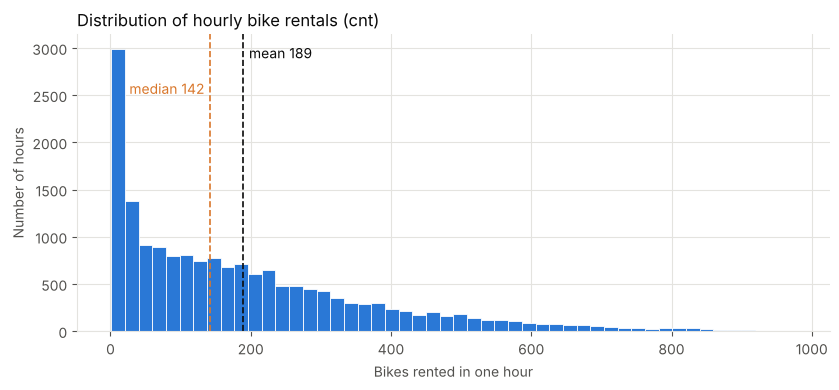

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(bike["cnt"], bins=50, color=BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(bike["cnt"].mean(), color=TEXT_COLOR, linestyle="--", linewidth=1.2)
ax.axvline(bike["cnt"].median(), color=ORANGE, linestyle="--", linewidth=1.2)
ymax = ax.get_ylim()[1]
ax.text(bike["cnt"].mean() + 8, ymax * 0.92, f"mean {bike['cnt'].mean():.0f}", color=TEXT_COLOR, fontsize=10)
ax.text(bike["cnt"].median() - 8, ymax * 0.80, f"median {bike['cnt'].median():.0f}", color=ORANGE, fontsize=10, ha="right")
ax.set_title("Distribution of hourly bike rentals (cnt)")
ax.set_xlabel("Bikes rented in one hour"); ax.set_ylabel("Number of hours")
plt.tight_layout(); plt.show()

### 4.2 Demand by hour of day (working days vs non-working days)

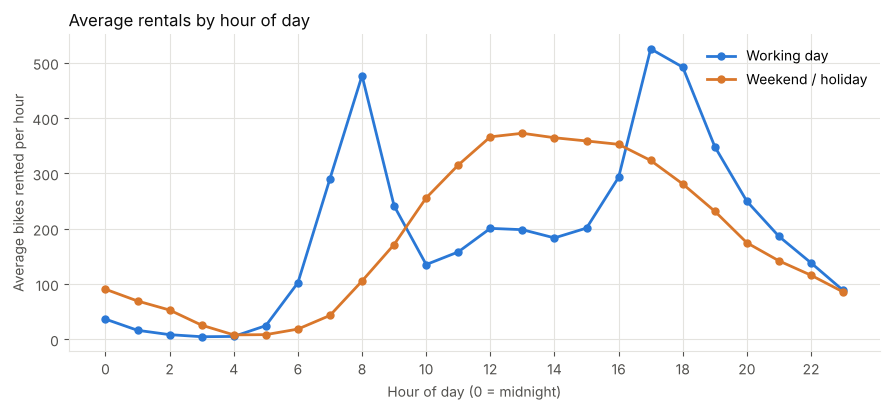

Busiest average hour on working days: 17:00 (525 bikes);  on weekends/holidays: 13:00 (373 bikes)


In [12]:
hourly = bike.groupby(["hr", "workingday"])["cnt"].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(hourly.index, hourly[1], color=BLUE, linewidth=2, marker="o", markersize=5, label="Working day")
ax.plot(hourly.index, hourly[0], color=ORANGE, linewidth=2, marker="o", markersize=5, label="Weekend / holiday")
ax.set_xticks(range(0, 24, 2)); ax.set_title("Average rentals by hour of day")
ax.set_xlabel("Hour of day (0 = midnight)"); ax.set_ylabel("Average bikes rented per hour"); ax.legend()
plt.tight_layout(); plt.show()
peak_work = hourly[1].idxmax(); peak_off = hourly[0].idxmax()
print(f"Busiest average hour on working days: {peak_work}:00 ({hourly[1].max():.0f} bikes);  on weekends/holidays: {peak_off}:00 ({hourly[0].max():.0f} bikes)")

### 4.3 Demand by weekday, season and weather

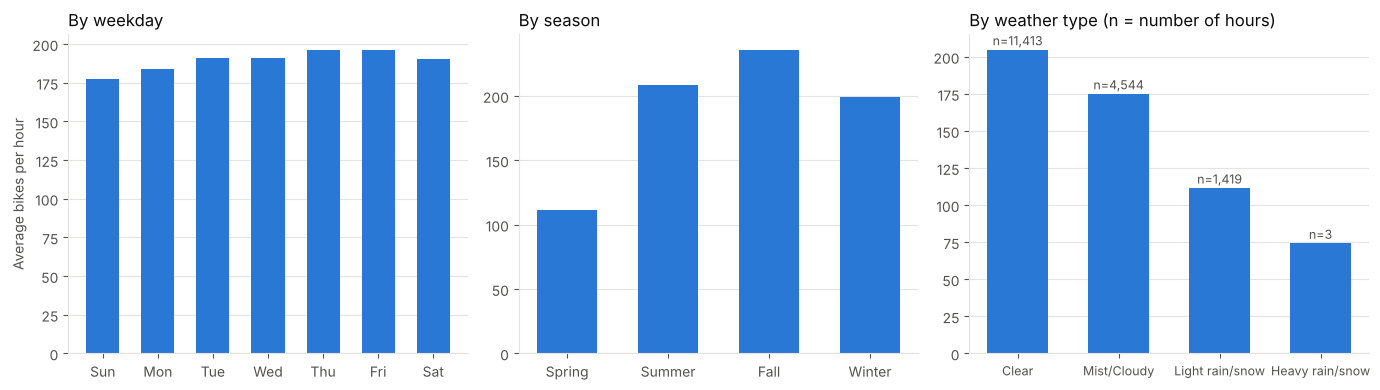

In [13]:
day_names = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
season_names = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_names = {1: "Clear", 2: "Mist/Cloudy", 3: "Light rain/snow", 4: "Heavy rain/snow"}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
wd = bike.groupby("weekday")["cnt"].mean()
axes[0].bar([day_names[i] for i in wd.index], wd.values, color=BLUE, width=0.6)
axes[0].set_title("By weekday"); axes[0].set_ylabel("Average bikes per hour")
se = bike.groupby("season")["cnt"].mean()
axes[1].bar([season_names[i] for i in se.index], se.values, color=BLUE, width=0.6)
axes[1].set_title("By season")
we = bike.groupby("weathersit")["cnt"].agg(["mean", "size"])
axes[2].bar([weather_names[i] for i in we.index], we["mean"].values, color=BLUE, width=0.6)
for i, (m, n) in enumerate(zip(we["mean"], we["size"])):
    axes[2].text(i, m + 3, f"n={n:,}", ha="center", color=MUTED_TEXT, fontsize=9)
axes[2].set_title("By weather type (n = number of hours)"); axes[2].tick_params(axis="x", labelsize=9)
for ax in axes: ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 4.4 Demand vs temperature, humidity and wind speed

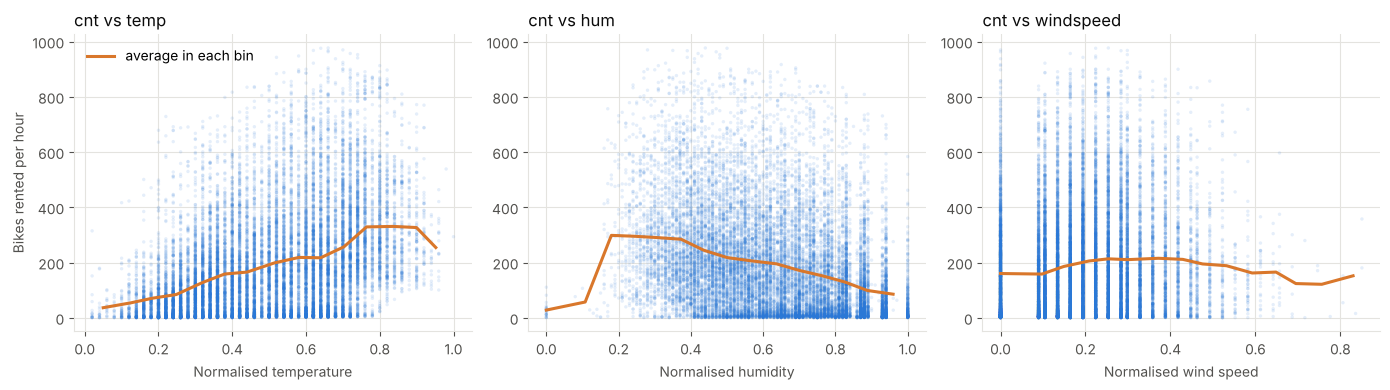

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, label in zip(axes, ["temp", "hum", "windspeed"],
                          ["Normalised temperature", "Normalised humidity", "Normalised wind speed"]):
    ax.scatter(bike[col], bike["cnt"], s=6, alpha=0.12, color=BLUE, edgecolors="none")
    bins = pd.cut(bike[col], bins=15)
    trend = bike.groupby(bins, observed=True).agg(x=(col, "mean"), y=("cnt", "mean"))
    ax.plot(trend["x"], trend["y"], color=ORANGE, linewidth=2.2, label="average in each bin")
    ax.set_xlabel(label); ax.set_title(f"cnt vs {col}")
axes[0].set_ylabel("Bikes rented per hour"); axes[0].legend()
plt.tight_layout(); plt.show()

### 4.5 Growth over the two years

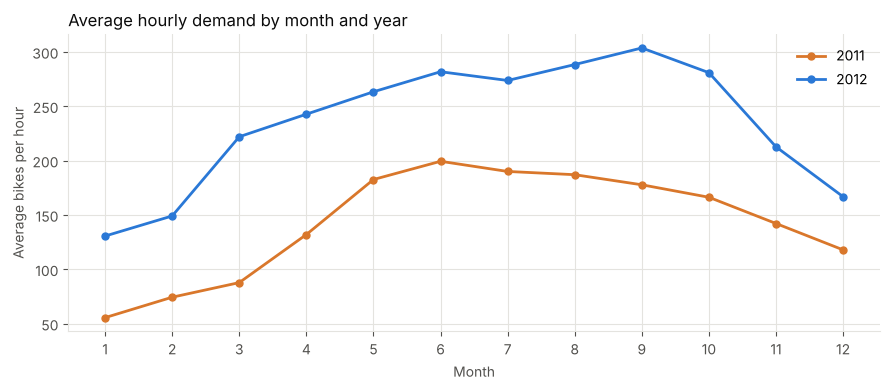

Average demand 2011: 144   |   2012: 235   (+63%)


In [15]:
monthly = bike.groupby(["yr", "mnth"])["cnt"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly[0], color=ORANGE, linewidth=2, marker="o", markersize=5, label="2011")
ax.plot(monthly.index, monthly[1], color=BLUE, linewidth=2, marker="o", markersize=5, label="2012")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("Average bikes per hour")
ax.set_title("Average hourly demand by month and year"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Average demand 2011: {bike[bike.yr==0]['cnt'].mean():.0f}   |   2012: {bike[bike.yr==1]['cnt'].mean():.0f}   (+{(bike[bike.yr==1]['cnt'].mean()/bike[bike.yr==0]['cnt'].mean()-1)*100:.0f}%)")

### 4.6 Correlation heatmap

`casual` and `registered` are drawn here **only to demonstrate the leakage problem**; they are not model inputs.

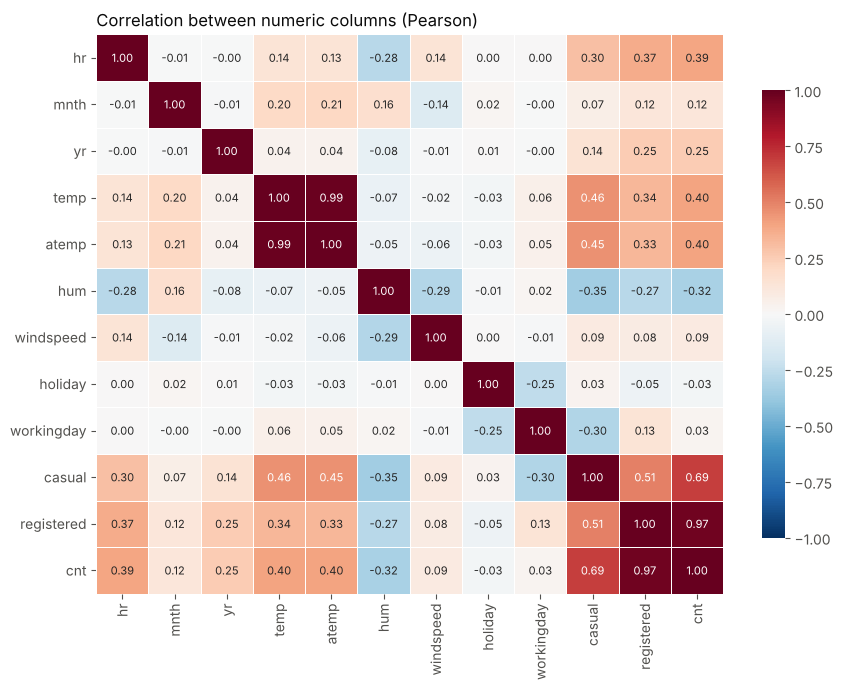

corr(temp, atemp) = 0.988  -> almost the same information (both kept; tree/NN/SVR models cope with this).
corr(cnt, registered) = 0.972, corr(cnt, casual) = 0.695 -> they are PARTS of the target (leakage).
corr(cnt, hr) = 0.394 is weak ONLY because the hour effect is not a straight line (two daily peaks, see 4.2).


In [16]:
corr_cols = ["hr", "mnth", "yr", "temp", "atemp", "hum", "windspeed", "holiday", "workingday", "casual", "registered", "cnt"]
corr = bike[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5,
            linecolor="white", annot_kws={"size": 8}, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation between numeric columns (Pearson)"); ax.grid(False)
plt.tight_layout(); plt.show()
print(f"corr(temp, atemp) = {corr.loc['temp','atemp']:.3f}  -> almost the same information (both kept; tree/NN/SVR models cope with this).")
print(f"corr(cnt, registered) = {corr.loc['cnt','registered']:.3f}, corr(cnt, casual) = {corr.loc['cnt','casual']:.3f} -> they are PARTS of the target (leakage).")
print(f"corr(cnt, hr) = {corr.loc['cnt','hr']:.3f} is weak ONLY because the hour effect is not a straight line (two daily peaks, see 4.2).")

### What the EDA tells us (read from the charts and numbers above)

1. **The hour of the day is the strongest pattern, and it differs between working and non-working days.** On working days there are two commute peaks, around **8:00 (≈ 477 rentals)** and **17:00 (≈ 525)**; on weekends/holidays there is one broad midday hump peaking at **13:00 (≈ 373)**. At 3:00 a working day averages only ≈ 5 rentals.
2. **Weekday alone matters little** (daily averages range only from about 177 to 196) – it matters through the *shape* of the day, which is why `workingday`, `weekday` and `hr` must be combined by the model (an interaction).
3. **Season and weather:** spring is the quietest season (≈ 111 rentals/hour) and fall the busiest (≈ 236). Clear weather averages ≈ 205, mist/cloud ≈ 175, light rain/snow ≈ 112. Heavy rain/snow has only **3 hours** in the whole dataset, so nothing reliable can be learned about it.
4. **Temperature, humidity and wind:** demand rises steadily with temperature (average ≈ 65 in the coldest fifth of readings vs ≈ 326 in the warmest) and falls with humidity (≈ 289 below 30 % vs ≈ 80 above 90 %). Wind speed has only a weak, non-linear relationship (correlation ≈ 0.09).
5. **Strong growth:** average demand rose from ≈ 144 (2011) to ≈ 235 (2012), **+63 %**, while both years follow the same seasonal shape. So `yr` is an important feature – and a warning that the model cannot be trusted for years outside 2011–2012.
6. **Redundant and leaking columns:** `temp` and `atemp` are almost identical (correlation 0.988). `registered` (0.97) and `casual` (0.70) correlate with `cnt` because they *add up to it*; they are excluded.
7. **What this means for modelling:** the relationship between inputs and demand is strongly **non-linear with interactions** (hour × working day × weather × temperature), and a straight-line model would struggle. Methods that can bend (kernels, neural networks, tree ensembles, boosting) are all sensible candidates – which is what we compare.
8. **A data quirk:** `season` changes in the middle of some months (e.g. March contains both season 1 and 2) because seasons follow astronomical dates. The web app therefore derives the season from the month using the most common label for that month.

# Step 5: Pre-processing, Feature Engineering and Leakage Prevention

### 5.1 Which columns are used (and which are not)

| Column | Decision | Reason |
|---|---|---|
| `instant` | **Dropped** | Only a row counter. It grows with time, so a flexible model could "memorise" the calendar from it without learning anything about demand. |
| `dteday` | **Dropped** | Its information is already in `yr`, `mnth`, `weekday`; the raw text date cannot be used by the models. |
| `casual`, `registered` | **Dropped – target leakage** | `cnt = casual + registered` in every row (Step 3.2). They are only known *after* the hour is over, so they can never be inputs of a forecast. |
| `yr, mnth, hr, season, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed` | **Used (12 inputs)** | All are known *before* the hour starts (calendar) or are available from a weather forecast. |

### 5.2 Pre-processing inside the pipeline

| Feature group | Columns | Step | Why |
|---|---|---|---|
| Numeric | `hr, mnth, temp, atemp, hum, windspeed` | **Impute** (median) → **Standard scaling** | SVR and the neural network are very sensitive to feature scale. (The data has no missing values, but the imputer makes the saved pipeline safe for the web app.) |
| **Cyclic hour (feature engineering)** | `hr` | **Periodic spline basis** (`SplineTransformer`, 24 bell-shaped functions, period 24) | Hour 23 and hour 0 are neighbours on the clock, but the numbers 23 and 0 are far apart. A periodic spline fixes this and also lets SVR/MLP draw the *two daily peaks* easily. It is a built-in scikit-learn step, so no custom code needs to be shipped to the web app. |
| Categorical | `season, weekday, weathersit` | **One-hot encoding** | They are labels, not quantities (Sunday is not "less than" Saturday). `handle_unknown="ignore"` keeps predictions working if a category is unseen in a training fold. |
| Binary | `yr, holiday, workingday` | Passed through | Already 0/1. |

**No outlier removal:** the busiest hours (up to 977 rentals) are real events (e.g. commute peaks on good-weather days), not errors. Deleting them would hide exactly the cases a fleet planner cares about.

**No log-transform of the target:** keeps the RMSE in plain "bikes per hour" (see Step 3.3).

### 5.3 Leakage prevention
Every learned step (imputer medians, scaler means/standard deviations, one-hot categories, the target scaler used by SVR/MLP) lives **inside the scikit-learn `Pipeline`**. In each of the 10 rounds the pipeline is **cloned and re-fitted on the 9 training folds only**, then applied to the test fold. Nothing is ever fitted on the full dataset before cross validation.

In [17]:
num_features = ["hr", "mnth", "temp", "atemp", "hum", "windspeed"]
cyc_features = ["hr"]                              # extra, cyclic encoding of the hour
cat_features = ["season", "weekday", "weathersit"]
bin_features = ["yr", "holiday", "workingday"]
target = "cnt"

FEATURES = ["yr", "mnth", "hr", "season", "holiday", "weekday", "workingday", "weathersit",
            "temp", "atemp", "hum", "windspeed"]   # the 12 raw input columns (this order is saved with the model)

X = bike[FEATURES]
y = bike[target]
print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of records : {len(X):,}")
print("Leakage columns excluded from X:", [c for c in ["casual", "registered", "instant", "dteday"] if c not in X.columns])

Input features (X): 12 columns -> ['yr', 'mnth', 'hr', 'season', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
Output (y)        : cnt
Number of records : 17,379
Leakage columns excluded from X: ['casual', 'registered', 'instant', 'dteday']


In [18]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
# Periodic spline for the hour: knots at 0,1,...,24 and period 24 (hour 24 == hour 0)
hour_spline = SplineTransformer(knots=np.linspace(0, 24, 25).reshape(-1, 1), degree=3, extrapolation="periodic")

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_features),
    ("hour_cyclic", hour_spline, cyc_features),
    ("cat", categorical_pipeline, cat_features),
    ("bin", "passthrough", bin_features),
])
print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('hour_cyclic', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

In [19]:
# For DISPLAY ONLY: fit a copy on the training part of the first fold to see how many model inputs the pipeline creates.
_tr, _te = next(KFold(n_splits=10, shuffle=True, random_state=SEED).split(X))
_demo = clone(preprocessor).fit(X.iloc[_tr])
print(f"12 raw columns  ->  {len(_demo.get_feature_names_out())} numeric model inputs (fitted on training fold 1 only)")
print("Examples:", list(_demo.get_feature_names_out()[:8]), "...")

12 raw columns  ->  48 numeric model inputs (fitted on training fold 1 only)
Examples: ['num__hr', 'num__mnth', 'num__temp', 'num__atemp', 'num__hum', 'num__windspeed', 'hour_cyclic__hr_sp_0', 'hour_cyclic__hr_sp_1'] ...


# Step 6: Define the 5 Regression Algorithms

| # | Algorithm (scikit-learn class) | How it predicts the rentals | What we want to learn about it |
|---|---|---|---|
| 1 | **Extra Trees** (`ExtraTreesRegressor`) | Builds 100 decision trees whose split points are chosen **at random**, then averages them | How well does a randomised tree ensemble capture the non-linear hour × weather × weekday pattern? |
| 2 | **AdaBoost** (`AdaBoostRegressor`) | Trains 50 *shallow* trees (depth 3) one after another; each new tree focuses on the hours the previous ones got most wrong | Is sequential re-weighting with weak learners enough? |
| 3 | **Support Vector Regression** (`SVR`, RBF kernel) | Fits a smooth curve in a high-dimensional space using the training hours that lie farthest from the curve (the *support vectors*) | Can a kernel method model the daily rhythm when the inputs and the target are scaled? |
| 4 | **MLP Neural Network** (`MLPRegressor`, 64-32 hidden units) | Learns weighted combinations of the inputs through two hidden layers by gradient descent | Does a small neural network beat the tree models? Does it converge? |
| 5 | **Histogram Gradient Boosting** (`HistGradientBoostingRegressor`) | Gradient boosting where features are first grouped into 255 bins, which makes training very fast | How does a modern, fast boosting method do on tabular data? |

**Compared with the instructor's Car Price notebooks** (Linear Regression, K-Nearest Neighbors, Decision Tree, Random Forest, Gradient Boosting): **none of our five classes is used there**, so the assignment condition is met. For full transparency: Extra Trees is a randomised relative of Random Forest, AdaBoost and Histogram Gradient Boosting are boosting methods like the instructor's `GradientBoostingRegressor`, but they are different algorithms/classes with different training procedures. The comparison therefore also shows how *these* relatives behave on a different problem.

**Fair-comparison rules**
- Same pre-processing, same 10 folds, same metrics for all five.
- **Fixed, reasonable settings, no hyper-parameter tuning** (as in the instructor's notebook): tuning on the same folds would make the cross-validation score optimistic.
- **SVR and MLP are wrapped in `TransformedTargetRegressor` with a `StandardScaler`.** Both algorithms assume targets near 0–1 scale; our target goes up to 977. The target scaler is fitted on the *training fold only* and predictions are automatically converted back to "bikes per hour", so RMSE stays in the original unit.
- **MLP convergence is monitored:** early stopping on a 10 % validation part *of the training fold*, at most 500 epochs, and we record the epochs used and any `ConvergenceWarning`.
- `random_state=42` everywhere. All other settings are scikit-learn defaults, except `C=10` for SVR (the default `C=1` tends to under-fit) and the MLP architecture (64-32 units with early stopping). These values were chosen in advance and **not tuned on the cross-validation results**.

In [20]:
algorithms = {
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(n_estimators=50, learning_rate=1.0, random_state=SEED),   # default weak learner: tree of depth 3
    "Support Vector Regression": TransformedTargetRegressor(
        regressor=SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale"), transformer=StandardScaler()),
    "MLP Neural Network": TransformedTargetRegressor(
        regressor=MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                               early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                               max_iter=500, random_state=SEED),
        transformer=StandardScaler()),
    "Histogram Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED),
}

print("Algorithms to compare:")
for number, (name, algo) in enumerate(algorithms.items(), start=1):
    print(f"  {number}. {name:<28} ->  {type(algo.regressor if hasattr(algo, 'regressor') else algo).__name__}")

instructor_algorithms = {"LinearRegression", "KNeighborsRegressor", "DecisionTreeRegressor", "RandomForestRegressor", "GradientBoostingRegressor"}
ours = {type(a.regressor if hasattr(a, "regressor") else a).__name__ for a in algorithms.values()}
print("\nOverlap with the instructor's Car Price algorithms:", ours & instructor_algorithms or "none")

Algorithms to compare:
  1. Extra Trees                  ->  ExtraTreesRegressor
  2. AdaBoost                     ->  AdaBoostRegressor
  3. Support Vector Regression    ->  SVR
  4. MLP Neural Network           ->  MLPRegressor
  5. Histogram Gradient Boosting  ->  HistGradientBoostingRegressor

Overlap with the instructor's Car Price algorithms: none


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds.
- `shuffle=True`: shuffle the rows first (the file is ordered by time).
- `random_state=42`: the **same folds are used for all 5 algorithms**, so every algorithm is tested on exactly the same hours.

In [21]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=SEED)
folds = list(kfold.split(X))                       # the same folds for every algorithm
print(f"{K}-Fold Cross Validation created (shuffle=True, random_state={SEED})")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

In [22]:
fold_info = []
for fold_number, (train_index, test_index) in enumerate(folds, start=1):
    fold_info.append({
        "Fold (Round)": fold_number,
        "Training Hours": len(train_index),
        "Testing Hours": len(test_index),
        "Avg Rentals in Test Fold": y.iloc[test_index].mean(),
        "Busiest Test Hour (rentals)": y.iloc[test_index].max(),
    })
fold_info_table = pd.DataFrame(fold_info).set_index("Fold (Round)")
assert sorted(np.concatenate([te for _, te in folds])) == list(range(len(X))), "every row must be tested exactly once"
print("Check passed: every hourly record is in the test fold exactly once.\n")
fold_info_table

Check passed: every hourly record is in the test fold exactly once.



,Training Hours,Testing Hours,Avg Rentals in Test Fold,Busiest Test Hour (rentals)
Fold (Round),,,,
1,15641,1738,183.82,901
2,15641,1738,186.20,977
3,15641,1738,185.95,899
4,15641,1738,189.78,941
5,15641,1738,190.28,943
6,15641,1738,187.55,913
7,15641,1738,193.52,968
8,15641,1738,196.39,963
9,15641,1738,195.21,976


# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). For each of the 10 folds we:

1. make a **fresh copy** (`clone`) so nothing learned in one round leaks into the next,
2. **train** it on the 9 training folds,
3. **predict** the 1 test fold,
4. calculate **RMSE, MAE and R²** for that fold (RMSE is the main metric).

### Progress bar (tqdm)
There is one step per algorithm per fold, so the bar has **5 × 10 = 50 steps**. It shows the algorithm and fold being trained, elapsed time, **estimated remaining time** and speed:

```
Support Vector Regression, fold 4/10:  58%|█████▊    | 29/50 [06:12<04:30, 12.9s/fold]
```
> The remaining time is an **estimate from the average speed so far**. SVR is much slower than the tree models, so the estimate changes as each algorithm runs.
>
> ⏱ **This step takes several minutes** (SVR dominates).

In [23]:
def inner_estimator(fitted_pipeline):
    """Return the real regressor inside the pipeline (unwraps TransformedTargetRegressor)."""
    est = fitted_pipeline.named_steps["regressor"]
    return getattr(est, "regressor_", est)

def run_cv(fold_list, title):
    """Run every algorithm on the given folds. Returns (results, out_of_fold_predictions)."""
    results = {n: {"rmse": [], "mae": [], "r2": [], "seconds": [], "iterations": [], "convergence_warnings": 0} for n in algorithms}
    oof = {n: np.full(len(X), np.nan) for n in algorithms}
    total_steps = len(algorithms) * len(fold_list)
    print(f"{title}: {len(algorithms)} algorithms x {len(fold_list)} folds = {total_steps} model fits")

    with tqdm(total=total_steps, unit="fold") as progress_bar:
        for name, algorithm in algorithms.items():
            model = Pipeline([("preprocessor", preprocessor), ("regressor", algorithm)])
            for fold_number, (train_index, test_index) in enumerate(fold_list, start=1):
                progress_bar.set_description(f"{name}, fold {fold_number}/{len(fold_list)}")
                start = time.time()
                fold_model = clone(model)                                  # fresh, untrained copy
                with warnings.catch_warnings(record=True) as caught:       # watch for non-convergence
                    warnings.simplefilter("always")
                    fold_model.fit(X.iloc[train_index], y.iloc[train_index])     # train on K-1 folds
                results[name]["convergence_warnings"] += sum(issubclass(w.category, ConvergenceWarning) for w in caught)
                predictions = fold_model.predict(X.iloc[test_index])               # test on 1 fold

                actual = y.iloc[test_index]
                results[name]["rmse"].append(np.sqrt(mean_squared_error(actual, predictions)))
                results[name]["mae"].append(mean_absolute_error(actual, predictions))
                results[name]["r2"].append(r2_score(actual, predictions))
                results[name]["iterations"].append(getattr(inner_estimator(fold_model), "n_iter_", np.nan))
                results[name]["seconds"].append(time.time() - start)
                oof[name][test_index] = predictions
                progress_bar.update(1)

            r = results[name]
            tqdm.write(f"{name:<28} -> mean RMSE = {np.mean(r['rmse']):>7.2f} bikes/hour   ({sum(r['seconds']):.1f} s)")
        progress_bar.set_description("Done")
    return results, oof

cv_results, cv_oof = run_cv(folds, f"{K}-fold cross validation")
print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

10-fold cross validation: 5 algorithms x 10 folds = 50 model fits

  0%|          | 0/50 [00:00<?, ?fold/s]

Extra Trees, fold 1/10:   0%|          | 0/50 [00:00<?, ?fold/s]

Extra Trees, fold 1/10:   2%|▏         | 1/50 [00:04<03:28,  4.26s/fold]

Extra Trees, fold 2/10:   2%|▏         | 1/50 [00:04<03:28,  4.26s/fold]

Extra Trees, fold 2/10:   4%|▍         | 2/50 [00:08<03:25,  4.27s/fold]

Extra Trees, fold 3/10:   4%|▍         | 2/50 [00:08<03:25,  4.27s/fold]

Extra Trees, fold 3/10:   6%|▌         | 3/50 [00:12<03:16,  4.17s/fold]

Extra Trees, fold 4/10:   6%|▌         | 3/50 [00:12<03:16,  4.17s/fold]

Extra Trees, fold 4/10:   8%|▊         | 4/50 [00:16<03:10,  4.15s/fold]

Extra Trees, fold 5/10:   8%|▊         | 4/50 [00:16<03:10,  4.15s/fold]

Extra Trees, fold 5/10:  10%|█         | 5/50 [00:20<03:06,  4.14s/fold]

Extra Trees, fold 6/10:  10%|█         | 5/50 [00:20<03:06,  4.14s/fold]

Extra Trees, fold 6/10:  12%|█▏        | 6/50 [00:25<03:08,  4.28s/fold]

Extra Trees, fold 7/10:  12%|█▏        | 6/50 [00:25<03:08,  4.28s/fold]

Extra Trees, fold 7/10:  14%|█▍        | 7/50 [00:29<03:04,  4.30s/fold]

Extra Trees, fold 8/10:  14%|█▍        | 7/50 [00:29<03:04,  4.30s/fold]

Extra Trees, fold 8/10:  16%|█▌        | 8/50 [00:34<03:02,  4.34s/fold]

Extra Trees, fold 9/10:  16%|█▌        | 8/50 [00:34<03:02,  4.34s/fold]

Extra Trees, fold 9/10:  18%|█▊        | 9/50 [00:38<02:59,  4.38s/fold]

Extra Trees, fold 10/10:  18%|█▊        | 9/50 [00:38<02:59,  4.38s/fold]

Extra Trees, fold 10/10:  20%|██        | 10/50 [00:42<02:53,  4.33s/fold]

Extra Trees, fold 10/10:  20%|██        | 10/50 [00:42<02:53,  4.33s/fold]

AdaBoost, fold 1/10:  20%|██        | 10/50 [00:42<02:53,  4.33s/fold]    

Extra Trees                  -> mean RMSE =   42.31 bikes/hour   (42.8 s)


AdaBoost, fold 1/10:  22%|██▏       | 11/50 [00:44<02:15,  3.48s/fold]

AdaBoost, fold 2/10:  22%|██▏       | 11/50 [00:44<02:15,  3.48s/fold]

AdaBoost, fold 2/10:  24%|██▍       | 12/50 [00:45<01:48,  2.85s/fold]

AdaBoost, fold 3/10:  24%|██▍       | 12/50 [00:45<01:48,  2.85s/fold]

AdaBoost, fold 3/10:  26%|██▌       | 13/50 [00:47<01:29,  2.41s/fold]

AdaBoost, fold 4/10:  26%|██▌       | 13/50 [00:47<01:29,  2.41s/fold]

AdaBoost, fold 4/10:  28%|██▊       | 14/50 [00:48<01:17,  2.14s/fold]

AdaBoost, fold 5/10:  28%|██▊       | 14/50 [00:48<01:17,  2.14s/fold]

AdaBoost, fold 5/10:  30%|███       | 15/50 [00:50<01:09,  1.97s/fold]

AdaBoost, fold 6/10:  30%|███       | 15/50 [00:50<01:09,  1.97s/fold]

AdaBoost, fold 6/10:  32%|███▏      | 16/50 [00:51<01:01,  1.81s/fold]

AdaBoost, fold 7/10:  32%|███▏      | 16/50 [00:51<01:01,  1.81s/fold]

AdaBoost, fold 7/10:  34%|███▍      | 17/50 [00:53<00:56,  1.70s/fold]

AdaBoost, fold 8/10:  34%|███▍      | 17/50 [00:53<00:56,  1.70s/fold]

AdaBoost, fold 8/10:  36%|███▌      | 18/50 [00:54<00:52,  1.63s/fold]

AdaBoost, fold 9/10:  36%|███▌      | 18/50 [00:54<00:52,  1.63s/fold]

AdaBoost, fold 9/10:  38%|███▊      | 19/50 [00:56<00:48,  1.55s/fold]

AdaBoost, fold 10/10:  38%|███▊      | 19/50 [00:56<00:48,  1.55s/fold]

AdaBoost, fold 10/10:  40%|████      | 20/50 [00:57<00:45,  1.52s/fold]

AdaBoost, fold 10/10:  40%|████      | 20/50 [00:57<00:45,  1.52s/fold]

Support Vector Regression, fold 1/10:  40%|████      | 20/50 [00:57<00:45,  1.52s/fold]

AdaBoost                     -> mean RMSE =  120.76 bikes/hour   (14.6 s)


Support Vector Regression, fold 1/10:  42%|████▏     | 21/50 [01:57<09:13, 19.10s/fold]

Support Vector Regression, fold 2/10:  42%|████▏     | 21/50 [01:57<09:13, 19.10s/fold]

Support Vector Regression, fold 2/10:  44%|████▍     | 22/50 [02:53<14:01, 30.07s/fold]

Support Vector Regression, fold 3/10:  44%|████▍     | 22/50 [02:53<14:01, 30.07s/fold]

Support Vector Regression, fold 3/10:  46%|████▌     | 23/50 [03:49<17:01, 37.82s/fold]

Support Vector Regression, fold 4/10:  46%|████▌     | 23/50 [03:49<17:01, 37.82s/fold]

Support Vector Regression, fold 4/10:  48%|████▊     | 24/50 [04:45<18:51, 43.53s/fold]

Support Vector Regression, fold 5/10:  48%|████▊     | 24/50 [04:45<18:51, 43.53s/fold]

Support Vector Regression, fold 5/10:  50%|█████     | 25/50 [05:41<19:37, 47.10s/fold]

Support Vector Regression, fold 6/10:  50%|█████     | 25/50 [05:41<19:37, 47.10s/fold]

Support Vector Regression, fold 6/10:  52%|█████▏    | 26/50 [06:37<19:58, 49.93s/fold]

Support Vector Regression, fold 7/10:  52%|█████▏    | 26/50 [06:37<19:58, 49.93s/fold]

Support Vector Regression, fold 7/10:  54%|█████▍    | 27/50 [07:36<20:09, 52.60s/fold]

Support Vector Regression, fold 8/10:  54%|█████▍    | 27/50 [07:36<20:09, 52.60s/fold]

Support Vector Regression, fold 8/10:  56%|█████▌    | 28/50 [08:30<19:27, 53.05s/fold]

Support Vector Regression, fold 9/10:  56%|█████▌    | 28/50 [08:30<19:27, 53.05s/fold]

Support Vector Regression, fold 9/10:  58%|█████▊    | 29/50 [09:27<18:53, 54.00s/fold]

Support Vector Regression, fold 10/10:  58%|█████▊    | 29/50 [09:27<18:53, 54.00s/fold]

Support Vector Regression, fold 10/10:  60%|██████    | 30/50 [10:30<18:54, 56.72s/fold]

Support Vector Regression, fold 10/10:  60%|██████    | 30/50 [10:30<18:54, 56.72s/fold]

MLP Neural Network, fold 1/10:  60%|██████    | 30/50 [10:30<18:54, 56.72s/fold]        

Support Vector Regression    -> mean RMSE =   39.27 bikes/hour   (572.6 s)


MLP Neural Network, fold 1/10:  62%|██████▏   | 31/50 [10:33<12:53, 40.72s/fold]

MLP Neural Network, fold 2/10:  62%|██████▏   | 31/50 [10:33<12:53, 40.72s/fold]

MLP Neural Network, fold 2/10:  64%|██████▍   | 32/50 [10:37<08:55, 29.77s/fold]

MLP Neural Network, fold 3/10:  64%|██████▍   | 32/50 [10:37<08:55, 29.77s/fold]

MLP Neural Network, fold 3/10:  66%|██████▌   | 33/50 [10:41<06:12, 21.91s/fold]

MLP Neural Network, fold 4/10:  66%|██████▌   | 33/50 [10:41<06:12, 21.91s/fold]

MLP Neural Network, fold 4/10:  68%|██████▊   | 34/50 [10:44<04:19, 16.20s/fold]

MLP Neural Network, fold 5/10:  68%|██████▊   | 34/50 [10:44<04:19, 16.20s/fold]

MLP Neural Network, fold 5/10:  70%|███████   | 35/50 [10:48<03:10, 12.67s/fold]

MLP Neural Network, fold 6/10:  70%|███████   | 35/50 [10:48<03:10, 12.67s/fold]

MLP Neural Network, fold 6/10:  72%|███████▏  | 36/50 [10:50<02:13,  9.51s/fold]

MLP Neural Network, fold 7/10:  72%|███████▏  | 36/50 [10:50<02:13,  9.51s/fold]

MLP Neural Network, fold 7/10:  74%|███████▍  | 37/50 [10:54<01:40,  7.69s/fold]

MLP Neural Network, fold 8/10:  74%|███████▍  | 37/50 [10:54<01:40,  7.69s/fold]

MLP Neural Network, fold 8/10:  76%|███████▌  | 38/50 [10:57<01:17,  6.45s/fold]

MLP Neural Network, fold 9/10:  76%|███████▌  | 38/50 [10:57<01:17,  6.45s/fold]

MLP Neural Network, fold 9/10:  78%|███████▊  | 39/50 [11:00<00:59,  5.43s/fold]

MLP Neural Network, fold 10/10:  78%|███████▊  | 39/50 [11:00<00:59,  5.43s/fold]

MLP Neural Network, fold 10/10:  80%|████████  | 40/50 [11:03<00:47,  4.72s/fold]

MLP Neural Network, fold 10/10:  80%|████████  | 40/50 [11:03<00:47,  4.72s/fold]

Histogram Gradient Boosting, fold 1/10:  80%|████████  | 40/50 [11:03<00:47,  4.72s/fold]

MLP Neural Network           -> mean RMSE =   40.85 bikes/hour   (33.7 s)


Histogram Gradient Boosting, fold 1/10:  82%|████████▏ | 41/50 [11:04<00:31,  3.50s/fold]

Histogram Gradient Boosting, fold 2/10:  82%|████████▏ | 41/50 [11:04<00:31,  3.50s/fold]

Histogram Gradient Boosting, fold 2/10:  84%|████████▍ | 42/50 [11:05<00:21,  2.63s/fold]

Histogram Gradient Boosting, fold 3/10:  84%|████████▍ | 42/50 [11:05<00:21,  2.63s/fold]

Histogram Gradient Boosting, fold 3/10:  86%|████████▌ | 43/50 [11:05<00:14,  2.06s/fold]

Histogram Gradient Boosting, fold 4/10:  86%|████████▌ | 43/50 [11:05<00:14,  2.06s/fold]

Histogram Gradient Boosting, fold 4/10:  88%|████████▊ | 44/50 [11:06<00:10,  1.67s/fold]

Histogram Gradient Boosting, fold 5/10:  88%|████████▊ | 44/50 [11:06<00:10,  1.67s/fold]

Histogram Gradient Boosting, fold 5/10:  90%|█████████ | 45/50 [11:07<00:06,  1.37s/fold]

Histogram Gradient Boosting, fold 6/10:  90%|█████████ | 45/50 [11:07<00:06,  1.37s/fold]

Histogram Gradient Boosting, fold 6/10:  92%|█████████▏| 46/50 [11:07<00:04,  1.18s/fold]

Histogram Gradient Boosting, fold 7/10:  92%|█████████▏| 46/50 [11:07<00:04,  1.18s/fold]

Histogram Gradient Boosting, fold 7/10:  94%|█████████▍| 47/50 [11:08<00:03,  1.02s/fold]

Histogram Gradient Boosting, fold 8/10:  94%|█████████▍| 47/50 [11:08<00:03,  1.02s/fold]

Histogram Gradient Boosting, fold 8/10:  96%|█████████▌| 48/50 [11:09<00:01,  1.08fold/s]

Histogram Gradient Boosting, fold 9/10:  96%|█████████▌| 48/50 [11:09<00:01,  1.08fold/s]

Histogram Gradient Boosting, fold 9/10:  98%|█████████▊| 49/50 [11:10<00:00,  1.14fold/s]

Histogram Gradient Boosting, fold 10/10:  98%|█████████▊| 49/50 [11:10<00:00,  1.14fold/s]

Histogram Gradient Boosting, fold 10/10: 100%|██████████| 50/50 [11:10<00:00,  1.25fold/s]

Histogram Gradient Boosting, fold 10/10: 100%|██████████| 50/50 [11:10<00:00,  1.25fold/s]

Done: 100%|██████████| 50/50 [11:10<00:00,  1.25fold/s]                                   

Done: 100%|██████████| 50/50 [11:10<00:00, 13.41s/fold]

Histogram Gradient Boosting  -> mean RMSE =   41.83 bikes/hour   (6.9 s)

10-fold cross validation completed for all 5 algorithms.


In [24]:
# Safety checks: all out-of-fold predictions exist and are finite; report MLP / boosting convergence information
for name in algorithms:
    assert np.isfinite(cv_oof[name]).all(), f"{name}: missing or non-finite predictions"
print("All 5 models produced a finite prediction for every one of the 17,379 hours.\n")

mlp = cv_results["MLP Neural Network"]
print("MLP convergence monitor:")
print(f"  epochs used per fold          : {[int(i) for i in mlp['iterations']]}   (limit = 500)")
print(f"  ConvergenceWarnings (10 folds): {mlp['convergence_warnings']}")
print("  -> early stopping ended training before the 500-epoch limit in every fold." if max(mlp['iterations']) < 500
      else "  -> WARNING: at least one fold reached the 500-epoch limit without converging.")
hgb = cv_results["Histogram Gradient Boosting"]
print(f"HistGradientBoosting boosting rounds used per fold: {[int(i) for i in hgb['iterations']]}")

All 5 models produced a finite prediction for every one of the 17,379 hours.

MLP convergence monitor:
  epochs used per fold          : [48, 65, 57, 45, 67, 36, 53, 59, 50, 47]   (limit = 500)
  ConvergenceWarnings (10 folds): 0
  -> early stopping ended training before the 500-epoch limit in every fold.
HistGradientBoosting boosting rounds used per fold: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round and each column an algorithm. The **lowest RMSE in each row** (best algorithm on that fold) is highlighted green. Count the green cells to see how often each algorithm **won a fold**.

In [25]:
def per_fold_frame(results, key):
    table = pd.DataFrame({n: results[n][key] for n in results})
    table.index = [f"Fold {i}" for i in range(1, len(table) + 1)]
    table.index.name = "Fold"
    return table

per_fold_table = per_fold_frame(cv_results, "rmse")
(per_fold_table.style
    .format("{:,.1f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Extra Trees,AdaBoost,Support Vector Regression,MLP Neural Network,Histogram Gradient Boosting
Fold,,,,,
Fold 1,41.2,119.0,37.9,38.6,40.2
Fold 2,42.6,118.9,41.2,42.0,42.7
Fold 3,38.7,121.1,34.6,38.1,38.0
Fold 4,44.1,122.6,41.2,41.9,44.0
Fold 5,43.4,122.1,40.9,42.0,42.3
Fold 6,42.1,119.4,41.0,43.3,43.1
Fold 7,41.4,120.2,37.8,39.2,40.5
Fold 8,41.9,120.4,39.6,40.1,42.6
Fold 9,43.3,123.0,38.6,41.2,42.0


## Step 9.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds, in **bikes per hour**. **Main ranking measure** (lower is better). |
| **Std RMSE** | Standard deviation of the 10 fold RMSEs. Small = consistent. |
| **Mean MAE** | Average absolute error (bikes per hour). Always ≤ RMSE; the gap shows how much a model has a few large errors. |
| **Mean R²** | Share of demand variation explained (1 = perfect, 0 = no better than predicting the average). |
| **Best / Worst Fold** | Lowest and highest fold RMSE. |
| **RMSE as % of Avg Demand** | Mean RMSE ÷ average hourly rentals – puts the error in context. |
| **Time** | Total train + predict time over the 10 folds on *this* machine. |
| **Rank** | 1 = lowest mean RMSE. |

In [26]:
def make_summary(results):
    rmse_t, mae_t, r2_t = (per_fold_frame(results, k) for k in ("rmse", "mae", "r2"))
    s = pd.DataFrame({
        "Mean RMSE": rmse_t.mean(),
        "Std RMSE": rmse_t.std(),                       # sample standard deviation (ddof=1) over the folds
        "Mean MAE": mae_t.mean(),
        "Mean R²": r2_t.mean(),
        "Best Fold RMSE": rmse_t.min(),
        "Worst Fold RMSE": rmse_t.max(),
        "RMSE as % of Avg Demand": rmse_t.mean() / y.mean() * 100,
        "Time (s)": pd.Series({n: sum(results[n]["seconds"]) for n in results}),
    }).sort_values("Mean RMSE")
    s.insert(0, "Rank", range(1, len(s) + 1))
    s.index.name = "Algorithm"
    return s

summary = make_summary(cv_results)
average_demand = y.mean()
print(f"Average demand in this data: {average_demand:,.1f} bikes per hour   |   reference: always predicting the average gives an RMSE of about {y.std():.0f}\n")

(summary.style
    .format({"Mean RMSE": "{:.2f}", "Std RMSE": "{:.2f}", "Mean MAE": "{:.2f}", "Mean R²": "{:.3f}",
             "Best Fold RMSE": "{:.2f}", "Worst Fold RMSE": "{:.2f}", "RMSE as % of Avg Demand": "{:.1f}%", "Time (s)": "{:.1f}"})
    .highlight_min(subset=["Mean RMSE", "Mean MAE"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;")
    .highlight_max(subset=["Mean R²"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average demand in this data: 189.5 bikes per hour   |   reference: always predicting the average gives an RMSE of about 181



,Rank,Mean RMSE,Std RMSE,Mean MAE,Mean R²,Best Fold RMSE,Worst Fold RMSE,RMSE as % of Avg Demand,Time (s)
Algorithm,,,,,,,,,
Support Vector Regression,1,39.27,2.10,25.36,0.953,34.63,41.25,20.7%,572.6
MLP Neural Network,2,40.85,1.75,25.97,0.949,38.09,43.31,21.6%,33.7
Histogram Gradient Boosting,3,41.83,1.77,26.40,0.947,37.98,44.03,22.1%,6.9
Extra Trees,4,42.31,1.65,25.19,0.945,38.75,44.33,22.3%,42.8
AdaBoost,5,120.76,1.47,106.20,0.556,118.89,123.01,63.7%,14.6


## Step 9.3: Visual Comparison

**Chart 1** – mean RMSE per algorithm (shorter bar = better); the black whisker is ± 1 standard deviation over the 10 folds.
**Chart 2** – the RMSE of **every individual fold** as a dot, so you can see the spread (consistency).
**Chart 3** – mean MAE (bikes per hour, lower is better) and **Chart 4** – mean R² (higher is better).

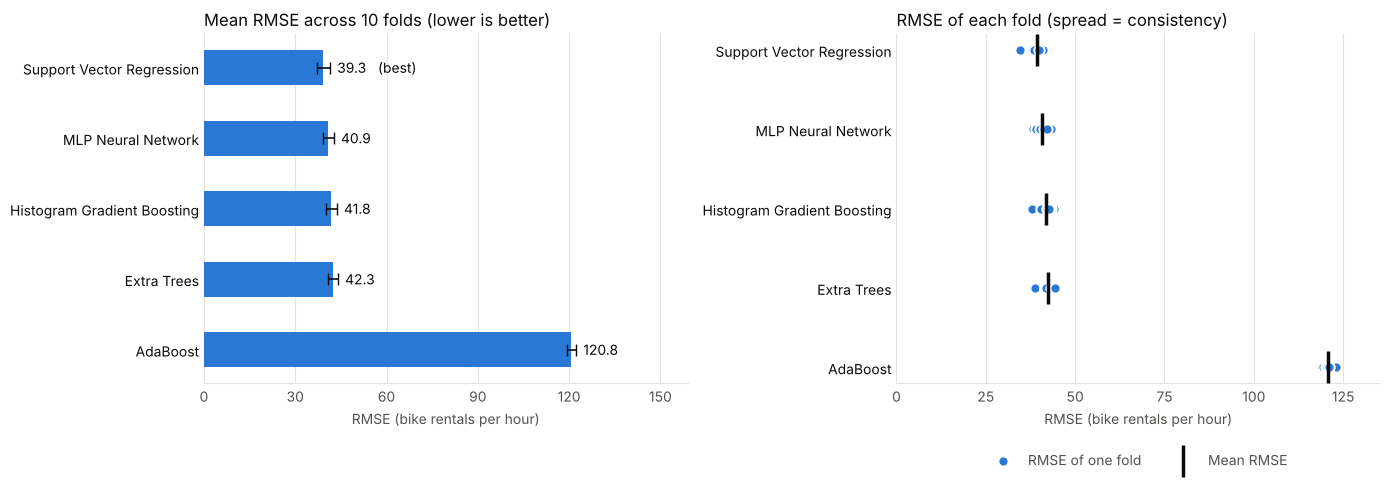

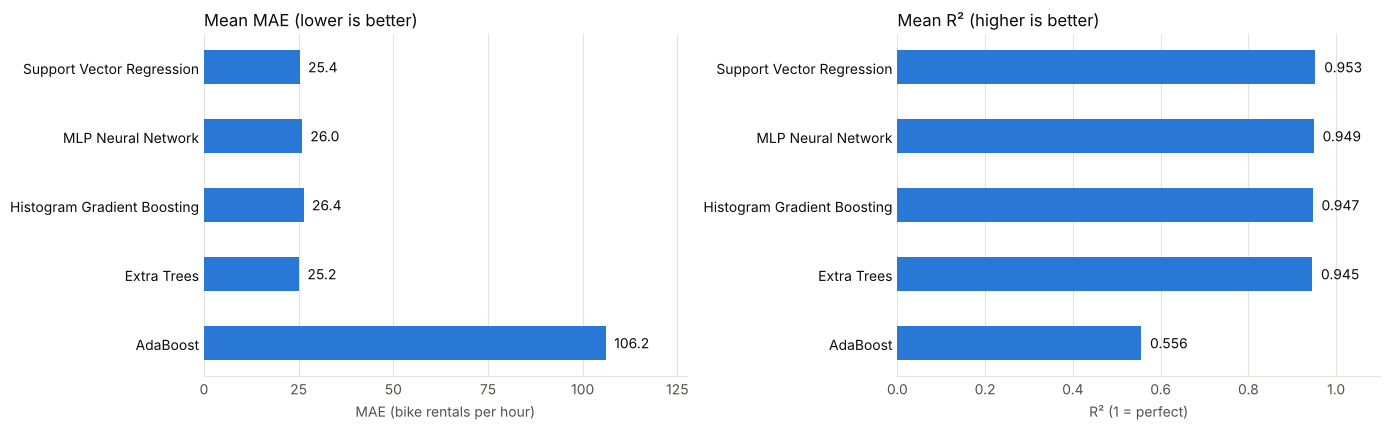

In [27]:
order = summary.index.tolist()               # best algorithm first
positions = np.arange(len(order))

def style_axis(ax, fmt="{:,.0f}"):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt.format(v)))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)

means, stds = summary["Mean RMSE"], summary["Std RMSE"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ---- Chart 1: mean RMSE with +/- 1 std ----
ax1.barh(positions, means, height=0.5, color=BLUE, xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, f"{means[name]:.1f}" + ("   (best)" if i == 0 else ""),
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR); ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3); style_axis(ax1)
ax1.set_title(f"Mean RMSE across {K} folds (lower is better)"); ax1.set_xlabel("RMSE (bike rentals per hour)")

# ---- Chart 2: RMSE of every fold ----
for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=55, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4, label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR); ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1); style_axis(ax2)
ax2.set_title("RMSE of each fold (spread = consistency)"); ax2.set_xlabel("RMSE (bike rentals per hour)")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, labelcolor=MUTED_TEXT)
plt.tight_layout(); plt.show()

# ---- Charts 3 and 4: MAE and R2 ----
fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(14, 4.4))
mae_vals, r2_vals = summary["Mean MAE"], summary["Mean R²"]
ax3.barh(positions, mae_vals, height=0.5, color=BLUE)
for i, name in enumerate(order):
    ax3.text(mae_vals[name] + mae_vals.max() * 0.02, i, f"{mae_vals[name]:.1f}", va="center", color=TEXT_COLOR, fontsize=10)
ax3.set_yticks(positions, order, color=TEXT_COLOR); ax3.invert_yaxis(); ax3.set_xlim(0, mae_vals.max() * 1.2); style_axis(ax3)
ax3.set_title("Mean MAE (lower is better)"); ax3.set_xlabel("MAE (bike rentals per hour)")
ax4.barh(positions, r2_vals, height=0.5, color=BLUE)
for i, name in enumerate(order):
    ax4.text(max(r2_vals[name], 0) + 0.02, i, f"{r2_vals[name]:.3f}", va="center", color=TEXT_COLOR, fontsize=10)
ax4.set_yticks(positions, order, color=TEXT_COLOR); ax4.invert_yaxis(); ax4.set_xlim(min(0, r2_vals.min() * 1.1), 1.1); style_axis(ax4, "{:.1f}")
ax4.set_title("Mean R² (higher is better)"); ax4.set_xlabel("R² (1 = perfect)")
plt.tight_layout(); plt.show()

## Step 9.4: Observations (calculated from the results above)

The statements below are **generated by code from the actual numbers**, so they cannot disagree with the tables.

In [28]:
best = order[0]; second = order[1]
gap = summary.loc[second, "Mean RMSE"] - summary.loc[best, "Mean RMSE"]
paired = per_fold_table[second] - per_fold_table[best]                     # positive = best algorithm better on that fold
wins = per_fold_table.idxmin(axis=1).value_counts().reindex(order).fillna(0).astype(int)
cv_ratio = (summary["Std RMSE"] / summary["Mean RMSE"]).sort_values()
ratio = (summary["Mean RMSE"] / summary["Mean MAE"])

print(f"1. LOWEST MEAN RMSE: {best} with {summary.loc[best,'Mean RMSE']:.2f} bikes/hour (std {summary.loc[best,'Std RMSE']:.2f}); "
      f"runner-up {second} with {summary.loc[second,'Mean RMSE']:.2f} (gap {gap:.2f}).")
print(f"2. IS THE WINNER CLEAR? {best} beat {second} on {int((paired>0).sum())} of {K} folds (paired difference per fold: mean {paired.mean():.2f}, std {paired.std():.2f}).")
print("3. FOLDS WON: " + ", ".join(f"{n} = {c}" for n, c in wins.items()))
print(f"4. CONSISTENCY (std/mean RMSE, smaller = steadier): " + ", ".join(f"{n} = {v:.3f}" for n, v in cv_ratio.items()))
print(f"5. RMSE vs MAE (RMSE/MAE ratio; bigger = more large errors): " + ", ".join(f"{n} = {v:.2f}" for n, v in ratio.items()))
print(f"6. ERROR IN CONTEXT: best RMSE = {summary.loc[best,'RMSE as % of Avg Demand']:.0f}% of the average hourly demand; R² = {summary.loc[best,'Mean R²']:.3f}.")
fastest = summary["Time (s)"].idxmin(); slowest = summary["Time (s)"].idxmax()
print(f"7. SPEED: fastest = {fastest} ({summary.loc[fastest,'Time (s)']:.1f} s), slowest = {slowest} ({summary.loc[slowest,'Time (s)']:.1f} s for 10 folds on this machine).")
worst = order[-1]
print(f"8. WEAKEST: {worst} (mean RMSE {summary.loc[worst,'Mean RMSE']:.2f}).")

1. LOWEST MEAN RMSE: Support Vector Regression with 39.27 bikes/hour (std 2.10); runner-up MLP Neural Network with 40.85 (gap 1.58).
2. IS THE WINNER CLEAR? Support Vector Regression beat MLP Neural Network on 10 of 10 folds (paired difference per fold: mean 1.58, std 1.00).
3. FOLDS WON: Support Vector Regression = 10, MLP Neural Network = 0, Histogram Gradient Boosting = 0, Extra Trees = 0, AdaBoost = 0
4. CONSISTENCY (std/mean RMSE, smaller = steadier): AdaBoost = 0.012, Extra Trees = 0.039, Histogram Gradient Boosting = 0.042, MLP Neural Network = 0.043, Support Vector Regression = 0.053
5. RMSE vs MAE (RMSE/MAE ratio; bigger = more large errors): Support Vector Regression = 1.55, MLP Neural Network = 1.57, Histogram Gradient Boosting = 1.58, Extra Trees = 1.68, AdaBoost = 1.14
6. ERROR IN CONTEXT: best RMSE = 21% of the average hourly demand; R² = 0.953.
7. SPEED: fastest = Histogram Gradient Boosting (6.9 s), slowest = Support Vector Regression (572.6 s for 10 folds on this machi

### Interpretation of the 10-fold results (numbers from this run)

> If you re-run the notebook, numbers can differ slightly with other library versions, but the pattern should be the same.

1. **Support Vector Regression has the lowest mean RMSE (39.27 bikes/hour, ≈ 21 % of the average demand, R² = 0.953)** and beat the runner-up (MLP, 40.85) on **all 10 folds**. However, the gap is only ≈ 1.6 bikes, and the four best models lie within ≈ 3 bikes of each other (39.3 – 42.3) while fold-to-fold standard deviations are ≈ 1.7 – 2.1. So SVR is the best *by the pre-declared rule*, but **MLP, Histogram Gradient Boosting and Extra Trees are practically close competitors**, and e.g. Histogram Gradient Boosting vs Extra Trees (41.8 vs 42.3) is essentially a tie.
2. **AdaBoost is clearly the worst (RMSE 120.76, R² = 0.556)** – about three times the error of the others, though it still beats the "always predict the average" reference (RMSE ≈ 181). Its errors are stable across folds (std 1.5) and its RMSE/MAE ratio is the smallest (1.14): it is wrong by a similar amount almost everywhere, which is consistent with **under-fitting** – 50 very shallow (depth-3) trees cannot represent the detailed hour × weather × working-day pattern. This is a fixed, un-tuned setting; a deeper base learner or more rounds would probably improve it.
3. **RMSE vs MAE:** Extra Trees has the *lowest MAE (25.19)* but the *highest RMSE of the four good models (42.31)*; its RMSE/MAE ratio (1.68) is the largest of the four, meaning that its few large mistakes (busy hours) are what hurt it. SVR, MLP and Histogram Gradient Boosting have ratios of about 1.55 – 1.58.
4. **No sign of over-fitting trouble in the CV scores,** because every score is computed on folds the model never trained on. The training error was deliberately not used.
5. **Convergence:** the MLP stopped by early stopping after 36 – 67 epochs (limit 500) in every fold with **no ConvergenceWarning**. Histogram Gradient Boosting used all **100 boosting rounds in every fold** – the default limit – so it may be slightly under-trained; allowing more rounds is a cheap improvement we did *not* make, because we did not tune on the CV folds.
6. **Computation trade-off:** SVR needed ≈ 573 s for 10 folds, Histogram Gradient Boosting only ≈ 7 s (≈ 80× faster) for an RMSE only ≈ 2.6 bikes higher. In a real system that retrains often, Histogram Gradient Boosting would be very attractive.
7. **Where the error is (Step 9.5):** the best model's error is largest at the **17:00 commute peak (RMSE ≈ 68)** and smallest at **3:00 (≈ 14)**. Errors grow with demand, so RMSE is dominated by busy hours.
8. **Negative predictions:** SVR predicted a negative count for 858 hours (4.9 %), the MLP for 552 and Histogram Gradient Boosting for 320; tree-averaging models (Extra Trees, AdaBoost) never do. Counts cannot be negative, so the web app clips predictions at 0 (clipping can only reduce the error); the CV numbers use raw predictions for all models.
9. **The most complex model did not win automatically:** a kernel method (SVR) beat a 100-tree ensemble and a neural network, but the simplest-looking *boosting* method (AdaBoost with default settings) was the worst.

## Step 9.5: Where Do the Errors Come From? (best model)

The out-of-fold predictions (every hour predicted by a model that never saw it) let us look at *when* the best model makes its largest mistakes.

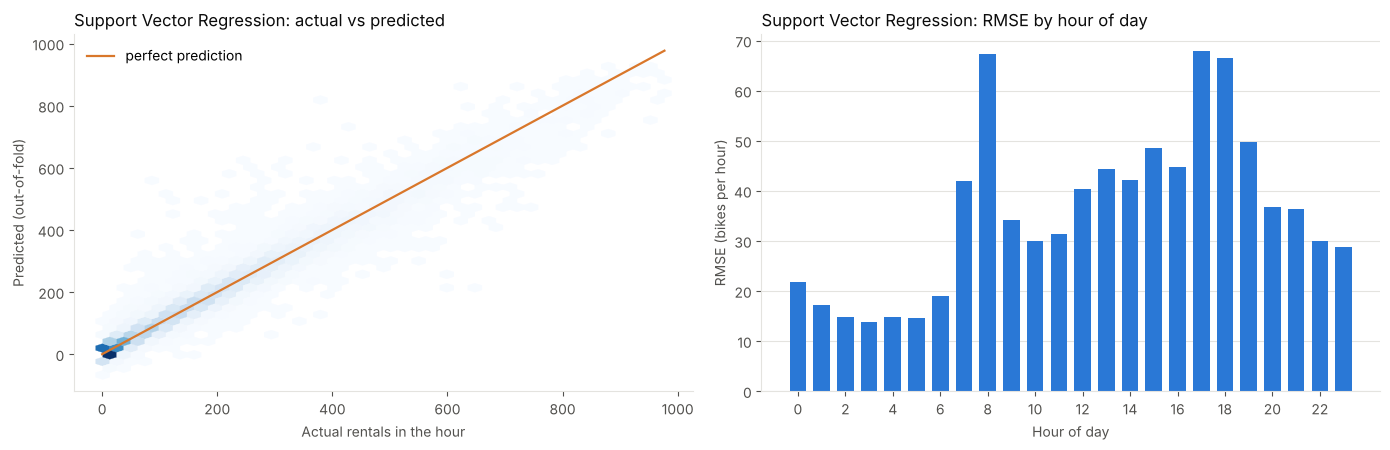

Hour with the largest error: 17:00 (RMSE 67.8);  smallest: 3:00 (RMSE 13.8)
Share of all hours predicted below 0 by Support Vector Regression: 4.94%
  Extra Trees                  predicted a negative count for    0 of 17,379 hours
  AdaBoost                     predicted a negative count for    0 of 17,379 hours
  Support Vector Regression    predicted a negative count for  858 of 17,379 hours
  MLP Neural Network           predicted a negative count for  552 of 17,379 hours
  Histogram Gradient Boosting  predicted a negative count for  320 of 17,379 hours


In [29]:
best_pred = cv_oof[best]
errors = pd.DataFrame({"hr": bike["hr"], "actual": y, "pred": best_pred})
errors["sq_err"] = (errors["actual"] - errors["pred"]) ** 2
rmse_by_hour = errors.groupby("hr")["sq_err"].mean().pow(0.5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
ax1.hexbin(errors["actual"], errors["pred"], gridsize=40, cmap="Blues", mincnt=1, linewidths=0.2)
lim = max(errors["actual"].max(), errors["pred"].max())
ax1.plot([0, lim], [0, lim], color=ORANGE, linewidth=1.6, label="perfect prediction")
ax1.set_xlabel("Actual rentals in the hour"); ax1.set_ylabel("Predicted (out-of-fold)")
ax1.set_title(f"{best}: actual vs predicted"); ax1.legend(loc="upper left"); ax1.grid(False)
ax2.bar(rmse_by_hour.index, rmse_by_hour.values, color=BLUE, width=0.7)
ax2.set_xticks(range(0, 24, 2)); ax2.set_xlabel("Hour of day"); ax2.set_ylabel("RMSE (bikes per hour)")
ax2.set_title(f"{best}: RMSE by hour of day"); ax2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"Hour with the largest error: {rmse_by_hour.idxmax()}:00 (RMSE {rmse_by_hour.max():.1f});  smallest: {rmse_by_hour.idxmin()}:00 (RMSE {rmse_by_hour.min():.1f})")
print(f"Share of all hours predicted below 0 by {best}: {(best_pred < 0).mean()*100:.2f}%")
for name in algorithms:
    print(f"  {name:<28} predicted a negative count for {int((cv_oof[name] < 0).sum()):>4} of {len(X):,} hours")

## Step 9.6: Extra Check – Day-Grouped Cross Validation (supplementary, not the assignment result)

**Why?** In the required shuffled 10-fold CV, hour 14:00 of a day may be in the *test* fold while 13:00 and 15:00 of the same day are in the *training* folds. Neighbouring hours share the same weather and the same demand level, so the test hours are "easier" than a truly new day. To measure this, we repeat the experiment with `GroupKFold`, where **all 24 hours of a day stay together** (a day is either entirely in training or entirely in testing).

> The **official comparison and the final model selection remain the shuffled 10-fold results above** (as required by the assignment). This section only shows how optimistic those numbers might be. It takes about as long as Step 8.

In [30]:
day_groups = bike["dteday"]
folds_grouped = list(GroupKFold(n_splits=K).split(X, y, groups=day_groups))
assert all(set(day_groups.iloc[tr]).isdisjoint(set(day_groups.iloc[te])) for tr, te in folds_grouped), "a day was split across train/test"
cv_results_g, cv_oof_g = run_cv(folds_grouped, f"Day-grouped {K}-fold cross validation")
summary_g = make_summary(cv_results_g)

Day-grouped 10-fold cross validation: 5 algorithms x 10 folds = 50 model fits


  0%|          | 0/50 [00:00<?, ?fold/s]

Extra Trees, fold 1/10:   0%|          | 0/50 [00:00<?, ?fold/s]

Extra Trees, fold 1/10:   2%|▏         | 1/50 [00:04<03:22,  4.13s/fold]

Extra Trees, fold 2/10:   2%|▏         | 1/50 [00:04<03:22,  4.13s/fold]

Extra Trees, fold 2/10:   4%|▍         | 2/50 [00:08<03:15,  4.06s/fold]

Extra Trees, fold 3/10:   4%|▍         | 2/50 [00:08<03:15,  4.06s/fold]

Extra Trees, fold 3/10:   6%|▌         | 3/50 [00:12<03:15,  4.15s/fold]

Extra Trees, fold 4/10:   6%|▌         | 3/50 [00:12<03:15,  4.15s/fold]

Extra Trees, fold 4/10:   8%|▊         | 4/50 [00:16<03:15,  4.25s/fold]

Extra Trees, fold 5/10:   8%|▊         | 4/50 [00:16<03:15,  4.25s/fold]

Extra Trees, fold 5/10:  10%|█         | 5/50 [00:20<03:08,  4.18s/fold]

Extra Trees, fold 6/10:  10%|█         | 5/50 [00:20<03:08,  4.18s/fold]

Extra Trees, fold 6/10:  12%|█▏        | 6/50 [00:25<03:04,  4.18s/fold]

Extra Trees, fold 7/10:  12%|█▏        | 6/50 [00:25<03:04,  4.18s/fold]

Extra Trees, fold 7/10:  14%|█▍        | 7/50 [00:29<02:59,  4.19s/fold]

Extra Trees, fold 8/10:  14%|█▍        | 7/50 [00:29<02:59,  4.19s/fold]

Extra Trees, fold 8/10:  16%|█▌        | 8/50 [00:33<02:52,  4.12s/fold]

Extra Trees, fold 9/10:  16%|█▌        | 8/50 [00:33<02:52,  4.12s/fold]

Extra Trees, fold 9/10:  18%|█▊        | 9/50 [00:37<02:51,  4.17s/fold]

Extra Trees, fold 10/10:  18%|█▊        | 9/50 [00:37<02:51,  4.17s/fold]

Extra Trees, fold 10/10:  20%|██        | 10/50 [00:41<02:48,  4.21s/fold]

Extra Trees, fold 10/10:  20%|██        | 10/50 [00:41<02:48,  4.21s/fold]

AdaBoost, fold 1/10:  20%|██        | 10/50 [00:41<02:48,  4.21s/fold]    

Extra Trees                  -> mean RMSE =   48.08 bikes/hour   (41.8 s)


AdaBoost, fold 1/10:  22%|██▏       | 11/50 [00:43<02:13,  3.42s/fold]

AdaBoost, fold 2/10:  22%|██▏       | 11/50 [00:43<02:13,  3.42s/fold]

AdaBoost, fold 2/10:  24%|██▍       | 12/50 [00:45<01:50,  2.90s/fold]

AdaBoost, fold 3/10:  24%|██▍       | 12/50 [00:45<01:50,  2.90s/fold]

AdaBoost, fold 3/10:  26%|██▌       | 13/50 [00:46<01:34,  2.56s/fold]

AdaBoost, fold 4/10:  26%|██▌       | 13/50 [00:46<01:34,  2.56s/fold]

AdaBoost, fold 4/10:  28%|██▊       | 14/50 [00:48<01:20,  2.25s/fold]

AdaBoost, fold 5/10:  28%|██▊       | 14/50 [00:48<01:20,  2.25s/fold]

AdaBoost, fold 5/10:  30%|███       | 15/50 [00:49<01:10,  2.01s/fold]

AdaBoost, fold 6/10:  30%|███       | 15/50 [00:49<01:10,  2.01s/fold]

AdaBoost, fold 6/10:  32%|███▏      | 16/50 [00:51<01:03,  1.85s/fold]

AdaBoost, fold 7/10:  32%|███▏      | 16/50 [00:51<01:03,  1.85s/fold]

AdaBoost, fold 7/10:  34%|███▍      | 17/50 [00:52<00:56,  1.71s/fold]

AdaBoost, fold 8/10:  34%|███▍      | 17/50 [00:52<00:56,  1.71s/fold]

AdaBoost, fold 8/10:  36%|███▌      | 18/50 [00:54<00:52,  1.65s/fold]

AdaBoost, fold 9/10:  36%|███▌      | 18/50 [00:54<00:52,  1.65s/fold]

AdaBoost, fold 9/10:  38%|███▊      | 19/50 [00:55<00:50,  1.64s/fold]

AdaBoost, fold 10/10:  38%|███▊      | 19/50 [00:55<00:50,  1.64s/fold]

AdaBoost, fold 10/10:  40%|████      | 20/50 [00:57<00:47,  1.58s/fold]

AdaBoost, fold 10/10:  40%|████      | 20/50 [00:57<00:47,  1.58s/fold]

Support Vector Regression, fold 1/10:  40%|████      | 20/50 [00:57<00:47,  1.58s/fold]

AdaBoost                     -> mean RMSE =  120.51 bikes/hour   (15.5 s)


Support Vector Regression, fold 1/10:  42%|████▏     | 21/50 [01:57<09:13, 19.07s/fold]

Support Vector Regression, fold 2/10:  42%|████▏     | 21/50 [01:57<09:13, 19.07s/fold]

Support Vector Regression, fold 2/10:  44%|████▍     | 22/50 [03:12<16:45, 35.93s/fold]

Support Vector Regression, fold 3/10:  44%|████▍     | 22/50 [03:12<16:45, 35.93s/fold]

Support Vector Regression, fold 3/10:  46%|████▌     | 23/50 [04:35<22:35, 50.21s/fold]

Support Vector Regression, fold 4/10:  46%|████▌     | 23/50 [04:35<22:35, 50.21s/fold]

Support Vector Regression, fold 4/10:  48%|████▊     | 24/50 [06:14<28:01, 64.68s/fold]

Support Vector Regression, fold 5/10:  48%|████▊     | 24/50 [06:14<28:01, 64.68s/fold]

Support Vector Regression, fold 5/10:  50%|█████     | 25/50 [07:37<29:17, 70.28s/fold]

Support Vector Regression, fold 6/10:  50%|█████     | 25/50 [07:37<29:17, 70.28s/fold]

Support Vector Regression, fold 6/10:  52%|█████▏    | 26/50 [08:57<29:15, 73.15s/fold]

Support Vector Regression, fold 7/10:  52%|█████▏    | 26/50 [08:57<29:15, 73.15s/fold]

Support Vector Regression, fold 7/10:  54%|█████▍    | 27/50 [10:23<29:30, 76.97s/fold]

Support Vector Regression, fold 8/10:  54%|█████▍    | 27/50 [10:23<29:30, 76.97s/fold]

Support Vector Regression, fold 8/10:  56%|█████▌    | 28/50 [11:54<29:48, 81.28s/fold]

Support Vector Regression, fold 9/10:  56%|█████▌    | 28/50 [11:54<29:48, 81.28s/fold]

Support Vector Regression, fold 9/10:  58%|█████▊    | 29/50 [13:23<29:14, 83.53s/fold]

Support Vector Regression, fold 10/10:  58%|█████▊    | 29/50 [13:23<29:14, 83.53s/fold]

Support Vector Regression, fold 10/10:  60%|██████    | 30/50 [14:54<28:32, 85.64s/fold]

Support Vector Regression, fold 10/10:  60%|██████    | 30/50 [14:54<28:32, 85.64s/fold]

MLP Neural Network, fold 1/10:  60%|██████    | 30/50 [14:54<28:32, 85.64s/fold]        

Support Vector Regression    -> mean RMSE =   47.22 bikes/hour   (836.7 s)


MLP Neural Network, fold 1/10:  62%|██████▏   | 31/50 [14:59<19:29, 61.54s/fold]

MLP Neural Network, fold 2/10:  62%|██████▏   | 31/50 [14:59<19:29, 61.54s/fold]

MLP Neural Network, fold 2/10:  64%|██████▍   | 32/50 [15:03<13:17, 44.31s/fold]

MLP Neural Network, fold 3/10:  64%|██████▍   | 32/50 [15:03<13:17, 44.31s/fold]

MLP Neural Network, fold 3/10:  66%|██████▌   | 33/50 [15:06<09:04, 32.01s/fold]

MLP Neural Network, fold 4/10:  66%|██████▌   | 33/50 [15:06<09:04, 32.01s/fold]

MLP Neural Network, fold 4/10:  68%|██████▊   | 34/50 [15:09<06:12, 23.25s/fold]

MLP Neural Network, fold 5/10:  68%|██████▊   | 34/50 [15:09<06:12, 23.25s/fold]

MLP Neural Network, fold 5/10:  70%|███████   | 35/50 [15:15<04:30, 18.05s/fold]

MLP Neural Network, fold 6/10:  70%|███████   | 35/50 [15:15<04:30, 18.05s/fold]

MLP Neural Network, fold 6/10:  72%|███████▏  | 36/50 [15:19<03:12, 13.74s/fold]

MLP Neural Network, fold 7/10:  72%|███████▏  | 36/50 [15:19<03:12, 13.74s/fold]

MLP Neural Network, fold 7/10:  74%|███████▍  | 37/50 [15:24<02:27, 11.32s/fold]

MLP Neural Network, fold 8/10:  74%|███████▍  | 37/50 [15:24<02:27, 11.32s/fold]

MLP Neural Network, fold 8/10:  76%|███████▌  | 38/50 [15:28<01:49,  9.09s/fold]

MLP Neural Network, fold 9/10:  76%|███████▌  | 38/50 [15:28<01:49,  9.09s/fold]

MLP Neural Network, fold 9/10:  78%|███████▊  | 39/50 [15:31<01:20,  7.30s/fold]

MLP Neural Network, fold 10/10:  78%|███████▊  | 39/50 [15:31<01:20,  7.30s/fold]

MLP Neural Network, fold 10/10:  80%|████████  | 40/50 [15:36<01:05,  6.57s/fold]

MLP Neural Network, fold 10/10:  80%|████████  | 40/50 [15:36<01:05,  6.57s/fold]

Histogram Gradient Boosting, fold 1/10:  80%|████████  | 40/50 [15:36<01:05,  6.57s/fold]

MLP Neural Network           -> mean RMSE =   44.55 bikes/hour   (42.6 s)


Histogram Gradient Boosting, fold 1/10:  82%|████████▏ | 41/50 [15:37<00:43,  4.87s/fold]

Histogram Gradient Boosting, fold 2/10:  82%|████████▏ | 41/50 [15:37<00:43,  4.87s/fold]

Histogram Gradient Boosting, fold 2/10:  84%|████████▍ | 42/50 [15:38<00:29,  3.66s/fold]

Histogram Gradient Boosting, fold 3/10:  84%|████████▍ | 42/50 [15:38<00:29,  3.66s/fold]

Histogram Gradient Boosting, fold 3/10:  86%|████████▌ | 43/50 [15:39<00:19,  2.85s/fold]

Histogram Gradient Boosting, fold 4/10:  86%|████████▌ | 43/50 [15:39<00:19,  2.85s/fold]

Histogram Gradient Boosting, fold 4/10:  88%|████████▊ | 44/50 [15:40<00:13,  2.29s/fold]

Histogram Gradient Boosting, fold 5/10:  88%|████████▊ | 44/50 [15:40<00:13,  2.29s/fold]

Histogram Gradient Boosting, fold 5/10:  90%|█████████ | 45/50 [15:41<00:09,  1.85s/fold]

Histogram Gradient Boosting, fold 6/10:  90%|█████████ | 45/50 [15:41<00:09,  1.85s/fold]

Histogram Gradient Boosting, fold 6/10:  92%|█████████▏| 46/50 [15:42<00:06,  1.53s/fold]

Histogram Gradient Boosting, fold 7/10:  92%|█████████▏| 46/50 [15:42<00:06,  1.53s/fold]

Histogram Gradient Boosting, fold 7/10:  94%|█████████▍| 47/50 [15:43<00:04,  1.34s/fold]

Histogram Gradient Boosting, fold 8/10:  94%|█████████▍| 47/50 [15:43<00:04,  1.34s/fold]

Histogram Gradient Boosting, fold 8/10:  96%|█████████▌| 48/50 [15:43<00:02,  1.19s/fold]

Histogram Gradient Boosting, fold 9/10:  96%|█████████▌| 48/50 [15:43<00:02,  1.19s/fold]

Histogram Gradient Boosting, fold 9/10:  98%|█████████▊| 49/50 [15:44<00:01,  1.11s/fold]

Histogram Gradient Boosting, fold 10/10:  98%|█████████▊| 49/50 [15:44<00:01,  1.11s/fold]

Histogram Gradient Boosting, fold 10/10: 100%|██████████| 50/50 [15:45<00:00,  1.08s/fold]

Histogram Gradient Boosting, fold 10/10: 100%|██████████| 50/50 [15:45<00:00,  1.08s/fold]

Done: 100%|██████████| 50/50 [15:45<00:00,  1.08s/fold]                                   

Done: 100%|██████████| 50/50 [15:45<00:00, 18.92s/fold]

Histogram Gradient Boosting  -> mean RMSE =   44.34 bikes/hour   (8.9 s)


In [31]:
compare = pd.DataFrame({
    "Mean RMSE – shuffled 10-fold (official)": summary["Mean RMSE"],
    "Rank (official)": summary["Rank"],
    "Mean RMSE – day-grouped 10-fold": summary_g["Mean RMSE"],
    "Rank (day-grouped)": summary_g["Rank"],
}).sort_values("Rank (official)")
compare["Extra error when whole days are unseen (%)"] = (compare["Mean RMSE – day-grouped 10-fold"] / compare["Mean RMSE – shuffled 10-fold (official)"] - 1) * 100
compare.style.format({"Mean RMSE – shuffled 10-fold (official)": "{:.2f}", "Mean RMSE – day-grouped 10-fold": "{:.2f}",
                      "Extra error when whole days are unseen (%)": "{:+.1f}%"})

,Mean RMSE – shuffled 10-fold (official),Rank (official),Mean RMSE – day-grouped 10-fold,Rank (day-grouped),Extra error when whole days are unseen (%)
Algorithm,,,,,
Support Vector Regression,39.27,1,47.22,3,+20.2%
MLP Neural Network,40.85,2,44.55,2,+9.1%
Histogram Gradient Boosting,41.83,3,44.34,1,+6.0%
Extra Trees,42.31,4,48.08,4,+13.6%
AdaBoost,120.76,5,120.51,5,-0.2%


### What the day-grouped check shows (numbers from this run)

- **All four good models become worse when whole days are unseen**: SVR +20 %, Extra Trees +14 %, MLP +9 %, Histogram Gradient Boosting +6 %. AdaBoost does not change (it was already under-fitting and does not exploit neighbouring hours).
- **The ranking changes:** Histogram Gradient Boosting (44.34) and MLP (44.55) are now ahead of SVR (47.22) and Extra Trees (48.08). SVR's advantage in the official shuffled CV therefore partly comes from smoothly interpolating between **neighbouring hours of the same day** – something that is not possible for a completely new day.
- **How to read this:** the official assignment result (shuffled 10-fold) is unchanged and SVR remains the selected model under the rule we declared in advance. But for the question "how accurate will the app be on a *new day*?", the day-grouped RMSE (about 44 – 47 bikes for the best three models) is the more realistic figure, and the top three models are within ≈ 3 bikes of each other. If you prefer to select the model by this stricter test, change `best_algorithm_name` in Step 10.1 – the rest of the notebook and the web app work unchanged.

# Step 10: Train, Save and Re-load the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built per algorithm were only used for measuring; they are now discarded. The selection rule is stated in advance: **lowest mean RMSE in the 10-fold cross validation of Step 8.**

In [32]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE"]
best_std_rmse  = summary.loc[best_algorithm_name, "Std RMSE"]
print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected error : RMSE = {best_mean_rmse:.2f} bikes/hour (+/- {best_std_rmse:.2f} across folds), MAE = {summary.loc[best_algorithm_name,'Mean MAE']:.2f}, R² = {summary.loc[best_algorithm_name,'Mean R²']:.3f}")

Best algorithm : Support Vector Regression
Expected error : RMSE = 39.27 bikes/hour (+/- 2.10 across folds), MAE = 25.36, R² = 0.953


## Step 10.2: Train the Best Algorithm on All the Data

The complete pipeline (pre-processing **and** algorithm) is fitted on **all 17,379 labelled hours** for deployment.

> ⚠️ **The model fitted on all data has no independent test set.** We therefore do **not** print a training-set error (it would be misleadingly low). The honest estimate of its future error is the cross-validation result above.

In [33]:
final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", clone(algorithms[best_algorithm_name])),
])
final_model.fit(X, y)
print(f"Final {best_algorithm_name} pipeline trained on {len(X):,} hourly records.")

Final Support Vector Regression pipeline trained on 17,379 hourly records.


## Step 10.3: Save the Trained Model (+ metadata for the web app)

We save the **whole fitted pipeline** with `joblib` (imputers, scaler, encoders, spline **and** the algorithm), so it predicts directly from the 12 raw input columns. A small JSON file stores the feature list, valid ranges, the cross-validation results and the library versions.

In [34]:
os.makedirs("model", exist_ok=True)
MODEL_FILE = "model/bike_demand_model.joblib"
META_FILE  = "model/model_metadata.json"
DOWNLOAD_FILES = False                 # set to True in Colab to download the files to your computer

joblib.dump(final_model, MODEL_FILE, compress=3)
print(f"Trained pipeline saved as '{MODEL_FILE}'  ({os.path.getsize(MODEL_FILE)/1024/1024:.2f} MB)")

# Facts the web app needs (all calculated from the data)
season_by_month = bike.groupby("mnth")["season"].agg(lambda s: int(s.mode().iloc[0])).to_dict()
slope, intercept = np.polyfit(bike["temp"], bike["atemp"], 1)
metadata = {
    "project": "Bike Rental Demand Prediction System",
    "created_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
    "model_name": best_algorithm_name,
    "estimator_class": type(inner_estimator(final_model)).__name__,
    "target": "cnt", "target_unit": "bike rentals per hour",
    "features": FEATURES,
    "feature_types": {"categorical": cat_features, "binary": bin_features, "numeric": ["mnth", "hr", "temp", "atemp", "hum", "windspeed"]},
    "n_training_rows": int(len(X)),
    "dataset": "UCI Bike Sharing Dataset, hour.csv (Fanaee-T & Gama, 2013)",
    "random_seed": SEED,
    "cross_validation": {
        "method": f"KFold(n_splits={K}, shuffle=True, random_state={SEED}) on all {len(X):,} labelled hours",
        "mean_rmse": float(best_mean_rmse), "std_rmse": float(best_std_rmse),
        "mean_mae": float(summary.loc[best_algorithm_name, "Mean MAE"]),
        "mean_r2": float(summary.loc[best_algorithm_name, "Mean R²"]),
    },
    "all_models_cv": {n: {"mean_rmse": float(r["Mean RMSE"]), "std_rmse": float(r["Std RMSE"]),
                          "mean_mae": float(r["Mean MAE"]), "mean_r2": float(r["Mean R²"])} for n, r in summary.iterrows()},
    "feature_ranges": {c: {"min": float(X[c].min()), "max": float(X[c].max())} for c in FEATURES},
    "weather_hours_in_training_data": {int(k): int(v) for k, v in bike["weathersit"].value_counts().sort_index().items()},
    "season_by_month": {int(k): int(v) for k, v in season_by_month.items()},
    "atemp_from_temp": {"slope": float(slope), "intercept": float(intercept)},
    "weekday_coding": "0 = Sunday ... 6 = Saturday (verified against the calendar in Step 3.2)",
    "scaling_from_readme": {"temp_divisor": 41, "atemp_divisor": 50, "hum_divisor": 100, "windspeed_divisor": 67},
    "library_versions": {"scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
}
with open(META_FILE, "w") as f:
    json.dump(metadata, f, indent=2)
print(f"Metadata saved as '{META_FILE}'")

# requirements.txt pinned to the versions that created the model file (a pickled model must be loaded with a compatible scikit-learn)
with open("requirements.txt", "w") as f:
    f.write(f"streamlit>=1.40\nscikit-learn=={sklearn.__version__}\nnumpy>={'.'.join(np.__version__.split('.')[:2])}\n"
            f"pandas>={'.'.join(pd.__version__.split('.')[:2])}\njoblib>={'.'.join(joblib.__version__.split('.')[:2])}\n")
print("requirements.txt written:\n" + open("requirements.txt").read())

if IN_COLAB and DOWNLOAD_FILES:
    for f in [MODEL_FILE, META_FILE, "requirements.txt"]:
        files.download(f)

Trained pipeline saved as 'model/bike_demand_model.joblib'  (0.26 MB)
Metadata saved as 'model/model_metadata.json'
requirements.txt written:
streamlit>=1.40
scikit-learn==1.9.1
numpy>=2.5
pandas>=3.0
joblib>=1.6



## Step 10.4: Re-load and Verify the Saved Model

In [35]:
loaded_model = joblib.load(MODEL_FILE)
sample = X.head(500)
assert list(loaded_model.feature_names_in_) == FEATURES, "feature schema of the saved model differs"
assert np.allclose(loaded_model.predict(sample), final_model.predict(sample)), "re-loaded model gives different predictions"
print(f"Re-loaded '{MODEL_FILE}': {type(inner_estimator(loaded_model)).__name__}")
print("Verified: same feature schema and identical predictions as the in-memory model on 500 records.")
print("Expected input columns:", list(loaded_model.feature_names_in_))

Re-loaded 'model/bike_demand_model.joblib': SVR
Verified: same feature schema and identical predictions as the in-memory model on 500 records.
Expected input columns: ['yr', 'mnth', 'hr', 'season', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example below, so **Run all** never stops. Set `USE_INTERACTIVE_INPUT = True` to type your own values. (The web app in Step 13 does the same with a friendly interface.)

> Temperature, humidity and wind speed are the dataset's **normalised** values (0 – 1). Example: `temp = 0.50`.

In [36]:
USE_INTERACTIVE_INPUT = False

example_input = {            # a mild, clear Thursday evening rush hour in 2012
    "yr": 1, "mnth": 6, "hr": 17, "season": 2, "holiday": 0, "weekday": 4, "workingday": 1,
    "weathersit": 1, "temp": 0.62, "atemp": 0.60, "hum": 0.50, "windspeed": 0.15,
}

def get_user_input():
    print("Enter the conditions (valid range seen in the data is shown):")
    r = metadata["feature_ranges"]
    return {c: (int if c in cat_features + bin_features + ["yr", "mnth", "hr"] else float)(
                input(f"{c} [{r[c]['min']:g} - {r[c]['max']:g}]: ")) for c in FEATURES}

user_input = get_user_input() if USE_INTERACTIVE_INPUT else example_input
print("Rental conditions:")
for feature, value in user_input.items():
    print(f"  {feature:<11}: {value}")

Rental conditions:
  yr         : 1
  mnth       : 6
  hr         : 17
  season     : 2
  holiday    : 0
  weekday    : 4
  workingday : 1
  weathersit : 1
  temp       : 0.62
  atemp      : 0.6
  hum        : 0.5
  windspeed  : 0.15


## Step 11.2: Convert User Input into a Feature Vector

The vector must have **exactly the same columns, in the same order,** as the training data. No manual encoding is needed – the saved pipeline scales, one-hot encodes and spline-encodes the hour automatically.

In [37]:
feature_vector = pd.DataFrame([user_input])[FEATURES]
feature_vector

,yr,mnth,hr,season,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,6,17,2,0,4,1,1,0.62,0.60,0.50,0.15


## Step 11.3 and 11.4: Load the Saved Model and Predict

Predicted demand: about 835 bikes in this hour   (raw model output: 835.17)
Typical error (cross-validation RMSE of Support Vector Regression): about +/- 39 bikes per hour.
This is an estimate, not a guarantee.


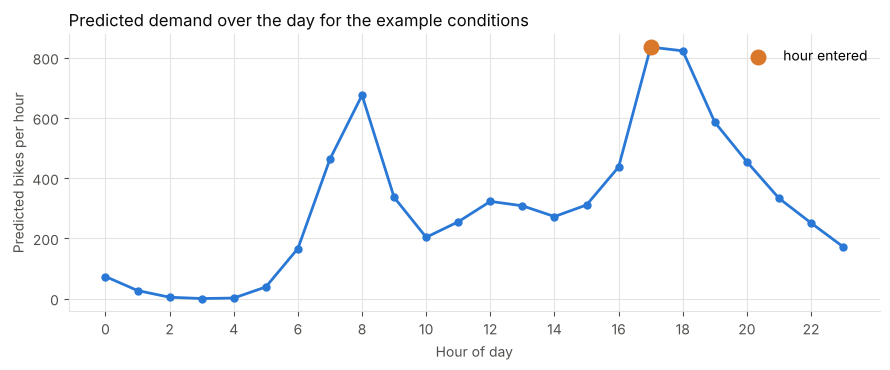

In [38]:
loaded_model = joblib.load(MODEL_FILE)
predicted = float(loaded_model.predict(feature_vector)[0])
print(f"Predicted demand: about {max(0, round(predicted))} bikes in this hour   (raw model output: {predicted:.2f})")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about +/- {best_mean_rmse:.0f} bikes per hour.")
print("This is an estimate, not a guarantee.")

# The same conditions for all 24 hours of that day (what the web app shows as a chart)
day_profile = pd.concat([feature_vector] * 24, ignore_index=True)
day_profile["hr"] = range(24)
day_profile_pred = np.clip(loaded_model.predict(day_profile), 0, None)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(24), day_profile_pred, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.scatter([user_input["hr"]], [day_profile_pred[user_input["hr"]]], s=110, color=ORANGE, zorder=5, label="hour entered")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day"); ax.set_ylabel("Predicted bikes per hour")
ax.set_title("Predicted demand over the day for the example conditions"); ax.legend()
plt.tight_layout(); plt.show()

# Step 12: Execute the Feedback Phase

After deployment, feedback from users and operators (e.g. bike-share staff) would be used to improve the system. Possible improvements:

1. **Hyper-parameter tuning** with nested cross validation (e.g. tree depth/number of trees, SVR `C`/`gamma`, MLP layer sizes). We deliberately used fixed settings for a fair, simple comparison.
2. **Time-aware features and validation:** lag features (demand 1 h / 24 h ago) are powerful but need live data at prediction time; use `TimeSeriesSplit` or day-grouped folds for validation (see Step 9.6).
3. **Real weather forecasts:** the app currently asks the user to type the weather; connecting a forecast API would make it automatic.
4. **Separate models for casual and registered riders** (their daily patterns differ), then add them up – allowed because they are predicted, not used as inputs.
5. **More recent and multi-city data:** the data covers only 2011–2012 in one city; demand today may differ.
6. **Predict a range, not a single number** (e.g. quantile regression) so planners can see the best/worst case.

# Step 13: Web Application and Cloud Deployment

The prediction web app is a **Streamlit** application (`app.py`) that loads the saved pipeline (`model/bike_demand_model.joblib`) and metadata, validates the inputs, and shows the predicted rentals.

### Project folder to upload to GitHub
```
bike-rental-demand/
├── app.py                          # the Streamlit web application
├── requirements.txt                # pinned libraries (written by Step 10.3)
├── README.md                       # deployment guide
├── .streamlit/config.toml          # theme
├── model/
│   ├── bike_demand_model.joblib    # saved fitted pipeline (Step 10.3)
│   └── model_metadata.json         # features, ranges, CV results, versions
├── data/hour.csv                   # dataset used for training (UCI, cite Fanaee-T & Gama 2013)
└── bike_rental_kfold_full_dataset_10fold.ipynb
```

### Run the app on your own computer (test first!)
```bash
pip install -r requirements.txt
streamlit run app.py
```

### Deploy to Streamlit Community Cloud (free)
1. Create a **GitHub** repository and upload the folder above (model file included; it must be < 100 MB for a normal GitHub upload).
2. Go to **https://share.streamlit.io**, sign in with GitHub, click **Create app → Deploy a public app from GitHub**.
3. Choose your repository, branch `main`, main file path `app.py`, then **Deploy**.
4. Wait for the build, open the generated `https://….streamlit.app` link, **test a few predictions**, and only then paste the link in the first cell of this notebook.

See `README.md` for troubleshooting (scikit-learn version mismatch, model file too large, etc.).

> The live URL at the top of this notebook is a **placeholder until you complete the steps above**.

In [39]:
# Quick check that the files the web app needs are present
for path in ["app.py", "requirements.txt", MODEL_FILE, META_FILE]:
    print(f"{'OK     ' if os.path.exists(path) else 'MISSING'} {path}")

OK      app.py
OK      requirements.txt
OK      model/bike_demand_model.joblib
OK      model/model_metadata.json


# Conclusion, Limitations and References
## Final Results Table (generated from this run)

In [40]:
final_table = summary[["Rank", "Mean RMSE", "Std RMSE", "Mean MAE", "Mean R²", "Time (s)"]]
final_table.style.format({"Mean RMSE": "{:.2f}", "Std RMSE": "{:.2f}", "Mean MAE": "{:.2f}", "Mean R²": "{:.3f}", "Time (s)": "{:.1f}"})

,Rank,Mean RMSE,Std RMSE,Mean MAE,Mean R²,Time (s)
Algorithm,,,,,,
Support Vector Regression,1,39.27,2.10,25.36,0.953,572.6
MLP Neural Network,2,40.85,1.75,25.97,0.949,33.7
Histogram Gradient Boosting,3,41.83,1.77,26.40,0.947,6.9
Extra Trees,4,42.31,1.65,25.19,0.945,42.8
AdaBoost,5,120.76,1.47,106.20,0.556,14.6


## Conclusion

In this notebook we compared **5 regression algorithms** – Extra Trees, AdaBoost, Support Vector Regression, an MLP neural network and Histogram Gradient Boosting – on the **full UCI Bike Sharing hourly dataset (17,379 labelled hours)** using **10-fold cross validation** and **RMSE** (plus MAE and R²), with identical folds, leakage-safe pipelines and no tuning on the folds.

- **Support Vector Regression achieved the lowest mean RMSE (≈ 39.3 bikes per hour, std ≈ 2.1, MAE ≈ 25.4, R² ≈ 0.953)**, followed by the MLP (≈ 40.9), Histogram Gradient Boosting (≈ 41.8), Extra Trees (≈ 42.3) and AdaBoost (≈ 120.8). SVR was trained on all 17,379 hours, saved together with its pre-processing pipeline (`joblib`), re-loaded and verified, and is served by the Streamlit web app.
- The four best models are within ≈ 3 bikes of each other; AdaBoost with default shallow trees under-fits clearly.
- Typical error ≈ 39 bikes per hour is about 21 % of the average demand; it is largest at the evening peak.

### Limitations (please read)
1. **Dataset size:** 17,379 rows is larger than the instructor's car dataset (11,914 rows, 11,199 after removing duplicates) but still only a *moderate* real-world dataset – not "big data".
2. **Optimistic validation:** neighbouring hours are highly similar, and shuffled K-fold puts them in both training and test folds. The day-grouped check (Step 9.6) gives 6 – 20 % higher RMSE for the good models and a different order of the top three. Real error on new days is therefore probably higher than 39 bikes.
3. **Only one city and two years;** demand grew 63 % from 2011 to 2012, so the model should not be used for other years or cities.
4. **Fixed, untuned settings:** results could change with tuning (e.g. Histogram Gradient Boosting used its 100-round limit in every fold; AdaBoost's weak learners are very shallow).
5. **Missing hours:** 165 hours are absent from `hour.csv`; the Readme does not say why.
6. **Temperature / wind scaling:** the Readme gives divisors (41, 50, 100, 67) that the app uses to turn friendly inputs into the model's normalised inputs; sources describe the temperature scaling inconsistently, so °C/km/h shown in the app are *dataset-scale* values.
7. **Rare weather:** heavy rain/snow occurs in only 3 hours – predictions for it are unreliable (the app warns).
8. **The deployed model has no independent test score;** its expected error is the cross-validation estimate.
9. **No external information** (events, holidays beyond the flag, real forecasts) is used.

## References

1. Fanaee-T, H., & Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge.* Progress in Artificial Intelligence, 1–15. Springer. doi:10.1007/s13748-013-0040-3
2. UCI Machine Learning Repository – Bike Sharing Dataset: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset (data originally from Capital Bikeshare, Washington D.C., and freemeteo.com weather data).
3. Kaggle – Bike Sharing Demand competition (same source data, different file layout): https://www.kaggle.com/competitions/bike-sharing-demand
4. scikit-learn documentation: `ExtraTreesRegressor`, `AdaBoostRegressor`, `SVR`, `MLPRegressor`, `HistGradientBoostingRegressor`, `KFold`, `GroupKFold`, `Pipeline`, `ColumnTransformer`, `SplineTransformer`, `TransformedTargetRegressor` – https://scikit-learn.org/stable/
5. Streamlit documentation and deployment guide – https://docs.streamlit.io/deploy/streamlit-community-cloud
6. Course material: MLF (AIC354) Car Price Prediction notebooks, Dr. Rao Muhammad Adeel Nawab and Mr. Airej Tashfeen (used as the structural reference for this assignment).